# Floor 3 Smart Building Analysis: candidate anomalies (CU-BEMS, Jul 2018 – Dec 2019)

**Owner:** Mik (Floor 3) · IS4001 Smart Building Analytics, Group 1

This notebook uses the Floor 3 files (`2018Floor3.csv`, `2019Floor3.csv`) to find **candidate anomalies** in energy use and indoor conditions. Every flagged pattern is a *candidate anomaly flagged for investigation*, not a confirmed fault. The dataset has no occupancy, CO₂/PM2.5 or outdoor-weather data, so no occupancy or air-quality conclusions are drawn. Outdoor weather comes from a cited external source (Section 5).

**Workflow:** set up the environment → load and map the columns → audit data quality transparently → resample to 15-min and hourly energy → define what "normal" looks like → detect anomalies (data-quality vs operational) → rank them → recommend actions and KPIs → state the assumptions.

Judgement calls are marked in the code with `# DECISION:` comments and collected in Section 10.

## 1. Setup

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

# Optional packages: the notebook falls back to cached files in data/external/ when they are missing.
try:
    import holidays
except ImportError:
    holidays = None
try:
    from astral import Observer
    from astral.sun import sun
except ImportError:
    Observer = sun = None
try:
    import requests
except ImportError:
    requests = None

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 25)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

# Chart style: fixed categorical order, thin marks, recessive grid.
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
MUTED, GRID, INK = '#898781', '#e1e0d9', '#52514e'
plt.rcParams.update({
    'figure.figsize': (12, 4), 'figure.dpi': 90, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.prop_cycle': plt.cycler(color=PALETTE), 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'lines.linewidth': 1.6, 'legend.frameon': False, 'legend.fontsize': 9,
})
END_USE_COLOURS = {'AC': PALETTE[0], 'Light': PALETTE[1], 'Plug': PALETTE[2]}

In [2]:
def find_repo_root(start=None):
    """Walk up from the working directory to the folder that holds data/ and README.md."""
    here = Path(start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / 'data').is_dir() and (candidate / 'README.md').is_file():
            return candidate
    raise FileNotFoundError('Repo root not found: start Jupyter from inside the is4001-g1-smart-building folder.')


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / 'data'
EXTERNAL_DIR = DATA_DIR / 'external'          # external data: never committed
OUTPUT_DIR = REPO_ROOT / 'workspace' / 'outputs'
EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FLOOR = 3
YEARS = (2018, 2019)
SOURCE_FILES = {year: DATA_DIR / f'{year}Floor{FLOOR}.csv' for year in YEARS}
TZ = 'Asia/Bangkok'                           # UTC+7, no daylight saving time
plt.rcParams['timezone'] = TZ                 # date axes in local time
SITE_LAT, SITE_LON = 13.738, 100.531          # approx. Chamchuri 5 building, Chulalongkorn University

# Business-hours constants. The nominal window is only a fallback: Section 6 derives the real schedule from the data.
NOMINAL_OPEN_HOUR, NOMINAL_CLOSE_HOUR = 8, 17
NIGHT_BASELOAD_HOURS = (1, 5)                 # [01:00, 05:00) local time is used to measure night-time baseload
SLOTS_PER_DAY = 96                            # 15-minute slots

CFG = {
    # DECISION: gaps of <= 5 min are linearly interpolated (a sensor or meter changes little in 5 min); longer gaps stay NaN.
    'short_gap_max_min': 5,
    # DECISION: a kW reading above 1.25 x that column's 99.99th percentile counts as a spike (suspected post-outage backfill).
    'spike_factor_p9999': 1.25,
    'temp_range_c': (10.0, 40.0),             # plausible indoor air temperature
    'rh_range_pct': (0.0, 100.0),
    'lux_range': (0.0, 2000.0),               # indoor ceiling sensor; the observed max is ~90 lux
    # DECISION: temperature/RH unchanged for >= 120 consecutive minutes is treated as a stuck sensor.
    'stuck_min_minutes': 120,
    # DECISION: a 15-min/hourly/daily value is used only when >= 80% of its minutes are valid (no scaling up of partial data).
    'min_coverage': 0.8,
    # DECISION: equipment counts as 'on' when above 30% of its own 99.9th-percentile kW.
    'on_frac_p999': 0.30,
    # DECISION: daily operating window = period when load exceeds baseload + 30% of (daily P95 - baseload).
    'schedule_on_frac': 0.30,
    # DECISION: comfort band 23-26 degC for an air-conditioned office in a tropical climate. Check against your course notes.
    'comfort_low_c': 23.0,
    'comfort_high_c': 26.0,
    # DECISION (assumption, needs a citable source): 3% extra AC energy per degC of over-cooling below comfort_low_c.
    'overcool_sensitivity_per_c': 0.03,
    'overcool_min_minutes': 60,               # an over-cooling day event needs >= 1 h below the comfort band
    'undercool_min_minutes': 60,
    'pulldown_exclusion_min': 60,             # ignore the first hour after AC switch-on (normal pull-down)
    'robust_z': 3.5,                          # robust z-score threshold (median/MAD), Iglewicz & Hoaglin convention
    # DECISION: after-hours interval flagged when > 0.2 kW above that circuit's night baseload (and above its robust threshold).
    'after_hours_min_excess_kw': 0.2,
    # DECISION: 30-min grace either side of the derived window absorbs day-to-day schedule jitter; events < 1 kWh are ignored.
    'schedule_grace_min': 30,
    'after_hours_min_event_kwh': 1.0,
    # DECISION: a public holiday whose daytime floor kWh >= 70% of a typical workday was evidently worked -> treated as a workday.
    'holiday_worked_frac': 0.70,
    'ac_self_min_excess_kwh': 1.0,
    # DECISION: an AC unit differs from its peers when its normalised daily kWh is > 1.5x or < 0.5x the peer median.
    'peer_ratio_high': 1.5,
    'peer_ratio_low': 0.5,
    # DECISION: a working day whose daytime floor kWh < 30% of the typical working day is treated as an unlisted closure day.
    'closure_day_frac': 0.30,
    # DECISION: flag lighting when estimated daylight lux >= 50% of the lamps' own lux contribution.
    'daylight_share_flag': 0.5,
    'residual_window_days': {'workday': 20, 'non_workday': 8},   # ~4 weeks of the same day class
    'residual_min_excess_kwh': 5.0,           # floor-level excess per hour needed before a residual is flagged
    'baseload_roll_days': 28,
}
print('Repo root:', REPO_ROOT.name, '| Floor', FLOOR, '| files:', ', '.join(p.name for p in SOURCE_FILES.values()))
assert all(p.exists() for p in SOURCE_FILES.values()), 'Floor 3 CSVs not found in data/.'

Repo root: is4001-g1-smart-building | Floor 3 | files: 2018Floor3.csv, 2019Floor3.csv


In [3]:
ANOMALY_COLUMNS = ['timestamp_start', 'timestamp_end', 'zone', 'variable', 'anomaly_type',
                   'magnitude', 'excess_kWh', 'rule_used']


def mad_scale(values):
    """Robust standard deviation estimate: 1.4826 x median absolute deviation."""
    values = np.asarray(values, dtype=float)
    return 1.4826 * np.nanmedian(np.abs(values - np.nanmedian(values)))


def run_lengths(mask):
    """Contiguous True runs of a boolean Series -> start, end, length and positions."""
    m = np.asarray(mask, dtype=np.int8)
    edges = np.diff(np.r_[0, m, 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1) - 1
    idx = mask.index
    return pd.DataFrame({'start': idx[starts], 'end': idx[ends], 'length': ends - starts + 1,
                         'start_pos': starts, 'end_pos': ends})


def interpolate_short_gaps(series, max_len):
    """Linearly fill NaN runs of length <= max_len that sit between valid values; leave longer gaps as NaN."""
    na = series.isna()
    run_id = na.ne(na.shift()).cumsum()
    run_len = na.groupby(run_id).transform('size')
    short = na & (run_len <= max_len)
    return series.mask(short, series.interpolate(limit_area='inside'))


def flagged_events(frame, flag_col, step, **agg):
    """Merge consecutive flagged rows (regular spacing `step`) into events with named aggregations."""
    flagged = frame[frame[flag_col]]
    if flagged.empty:
        return pd.DataFrame()
    step = pd.Timedelta(step)
    times = flagged.index.to_series()
    event_id = (times.diff() != step).cumsum().to_numpy()
    out = flagged.groupby(event_id).agg(**agg)
    out['timestamp_start'] = times.groupby(event_id).min().to_numpy()
    out['timestamp_end'] = times.groupby(event_id).max().to_numpy() + step
    out['n_intervals'] = times.groupby(event_id).size().to_numpy()
    return out.reset_index(drop=True)


def to_records(events, **constant_fields):
    """Shape an events table into the standard anomaly columns."""
    out = events.copy()
    for key, value in constant_fields.items():
        out[key] = value
    for col in ANOMALY_COLUMNS:
        if col not in out:
            out[col] = np.nan
    return out[ANOMALY_COLUMNS]


def label_axes(ax, title, xlabel, ylabel, legend=True):
    ax.set_title(title, loc='left')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend()
    return ax


def slot_to_time(slot):
    """15-min slot number (0-96) -> 'HH:MM'."""
    if pd.isna(slot):
        return 'n/a'
    minutes = int(round(slot)) * 15
    return f'{minutes // 60:02d}:{minutes % 60:02d}'

## 2. Problem & Questions

The brief asks for two distinct building-performance questions. Each question must state who benefits, what evidence answers it, the method, the facilities-management (FM) action, and a measurable KPI. The drafts below are **suggestions based on what this notebook found**. Edit them before the group decides.

### Question A (energy / operations): *draft*
> **Is Floor 3's air-conditioning over-cooling its zones and running outside its normal schedule, and how much energy does that represent?**
- **Stakeholder:** Chulalongkorn Office of Physical Resources Management (FM / energy manager); occupants (thermal comfort).
- **Evidence:** zone AC kW against zone temperature, the derived AC schedule, after-hours AC energy, and weather-normalised daily AC kWh (Sections 6, 7a, 7c, 7e).
- **Method:** empirical schedule plus a night-baseload baseline; comfort-band rule on the AC-on periods; robust (median/MAD) residuals.
- **FM action:** _(fill in: e.g. raise the cooling setpoint towards 25 °C in zones 4–5, tighten the start/stop times)_
- **KPI:** _(fill in: e.g. % of AC-on time with zone temperature < 23 °C; after-hours AC kWh per week)_

### Question B (anomaly detection / data reliability): *draft*
> **Can a transparent baseline flag abnormal energy periods and unreliable sensors early enough for FM to act, without false alarms from holidays and hot weather?**
- **Stakeholder:** FM operations / BMS technicians; the university IT/network team (meter outages).
- **Evidence:** the data-quality audit (gaps, spikes), the time-of-week baseline residuals, the holiday calendar and outdoor weather (Sections 4, 7e, 8).
- **Method:** rolling same-slot median baseline, a MAD threshold, holiday/closure-day handling, and a weather-normalised check.
- **FM action:** _(fill in: e.g. a weekly exception report; a meter-communication alarm when data is missing for > 1 h)_
- **KPI:** _(fill in: e.g. excess kWh per month above baseline; % of 15-min intervals with valid data; false-alarm share on holidays)_

## 3. Data Loading

Both years are loaded with `float32` dtypes to save memory. `Date` is parsed and localised to Bangkok time (UTC+7). The CSV timestamps are local wall-clock time and Thailand has no daylight saving, so the localisation is unambiguous. Zones, end-uses and units are inferred from the column headers.

In [4]:
def load_floor_year(path):
    """Read one floor-year CSV with compact dtypes; returns the raw frame (Date still a column)."""
    header = pd.read_csv(path, nrows=0).columns
    frame = pd.read_csv(path, dtype={c: 'float32' for c in header if c != 'Date'})
    frame['Date'] = pd.to_datetime(frame['Date'], format='%Y-%m-%d %H:%M:%S')
    return frame


raw_frames, file_audit = {}, []
for year, path in SOURCE_FILES.items():
    frame = load_floor_year(path)
    raw_frames[year] = frame
    diffs = frame['Date'].diff()
    file_audit.append({
        'year': year, 'file': path.name, 'rows': len(frame), 'data_columns': frame.shape[1] - 1,
        'first': frame['Date'].min(), 'last': frame['Date'].max(),
        'duplicate_timestamps': int(frame['Date'].duplicated().sum()),
        'out_of_order_rows': int((diffs < pd.Timedelta(0)).sum()),
        'all_nan_rows': int(frame.drop(columns='Date').isna().all(axis=1).sum()),
    })
file_audit = pd.DataFrame(file_audit)
display(file_audit)

headers = {year: list(f.columns) for year, f in raw_frames.items()}
assert headers[2018] == headers[2019], 'The two years have different columns.'

,year,file,rows,data_columns,first,last,duplicate_timestamps,out_of_order_rows,all_nan_rows
0,2018,2018Floor3.csv,264960,29,2018-07-01,2018-12-31 23:59:00,0,0,59101
1,2019,2019Floor3.csv,525600,29,2019-01-01,2019-12-31 23:59:00,0,0,409


In [5]:
COLUMN_PATTERN = re.compile(r'^z(?P<zone>\d+)_(?P<device>AC\d+|Light|Plug|S\d+)\((?P<unit>kW|degC|RH%|lux)\)$')
SENSOR_QUANTITY = {'degC': ('temperature', 'temp_c'), 'RH%': ('humidity', 'rh_pct'), 'lux': ('illuminance', 'lux')}


def parse_column(name):
    """'z1_AC4(kW)' -> zone z1, end-use AC, device AC4, unit kW, tidy name z1_ac4_kw."""
    m = COLUMN_PATTERN.match(name)
    if m is None:
        raise ValueError(f'Unrecognised column: {name}')
    zone, device, unit = f"z{m['zone']}", m['device'], m['unit']
    if unit == 'kW':
        end_use = 'AC' if device.startswith('AC') else device
        return dict(original=name, tidy=f'{zone}_{device.lower()}_kw', zone=zone, end_use=end_use,
                    device=device, quantity='power', unit=unit)
    quantity, suffix = SENSOR_QUANTITY[unit]
    return dict(original=name, tidy=f'{zone}_{suffix}', zone=zone, end_use='Sensor',
                device=device, quantity=quantity, unit=unit)


col_map = pd.DataFrame([parse_column(c) for c in headers[2019] if c != 'Date'])

floor = pd.concat(raw_frames.values(), ignore_index=True).rename(columns=dict(zip(col_map.original, col_map.tidy)))
del raw_frames
# DECISION: sort by time and keep the first row of any duplicate timestamp (the audit above found none).
floor = floor.sort_values('Date').drop_duplicates('Date', keep='first').set_index('Date')
floor.index = floor.index.tz_localize(TZ)
floor.index.name = 'timestamp'

POWER_COLS = col_map.loc[col_map.quantity == 'power', 'tidy'].tolist()
ENV_COLS = col_map.loc[col_map.quantity != 'power', 'tidy'].tolist()
TEMP_COLS = col_map.loc[col_map.quantity == 'temperature', 'tidy'].tolist()
RH_COLS = col_map.loc[col_map.quantity == 'humidity', 'tidy'].tolist()
LUX_COLS = col_map.loc[col_map.quantity == 'illuminance', 'tidy'].tolist()
AC_COLS = col_map.loc[col_map.end_use == 'AC', 'tidy'].tolist()
ZONES = sorted(col_map.zone.unique())

# AC unit class from the CU-BEMS data descriptor: EMU-metered wall-mounted split units are 1-2 kW;
# digital meters measure large AC compressors of 20-40 kW. Inferred here from each unit's 99.9th percentile.
p999 = floor[POWER_COLS].quantile(0.999)
col_map['p99.9_kw'] = col_map.tidy.map(p999).round(2)
col_map['ac_class'] = np.where(col_map.end_use != 'AC', '',
                               np.where(col_map['p99.9_kw'] > 5, 'large compressor (20-40 kW class)',
                                        'wall-mounted split (1-2 kW class)'))
LARGE_AC = col_map.loc[col_map.ac_class.str.startswith('large'), 'tidy'].tolist()
SPLIT_AC = col_map.loc[col_map.ac_class.str.startswith('wall'), 'tidy'].tolist()

print(f'Combined: {floor.shape[0]:,} rows x {floor.shape[1]} columns, '
      f'{floor.memory_usage(deep=True).sum() / 1e6:.0f} MB, {floor.index.min()} -> {floor.index.max()}')
print('Zones:', ZONES, '| large AC:', LARGE_AC, '| split AC:', SPLIT_AC)
with pd.option_context('display.max_rows', 40):
    display(col_map)

Combined: 790,560 rows x 29 columns, 98 MB, 2018-07-01 00:00:00+07:00 -> 2019-12-31 23:59:00+07:00
Zones: ['z1', 'z2', 'z3', 'z4', 'z5'] | large AC: ['z1_ac4_kw', 'z2_ac1_kw', 'z4_ac1_kw', 'z5_ac1_kw'] | split AC: ['z1_ac1_kw', 'z1_ac2_kw', 'z1_ac3_kw']


,original,tidy,zone,end_use,device,quantity,unit,p99.9_kw,ac_class
0,z1_AC1(kW),z1_ac1_kw,z1,AC,AC1,power,kW,1.590,wall-mounted split (1-2 kW class)
1,z1_AC2(kW),z1_ac2_kw,z1,AC,AC2,power,kW,2.690,wall-mounted split (1-2 kW class)
2,z1_AC3(kW),z1_ac3_kw,z1,AC,AC3,power,kW,1.290,wall-mounted split (1-2 kW class)
3,z1_AC4(kW),z1_ac4_kw,z1,AC,AC4,power,kW,38.710,large compressor (20-40 kW class)
4,z1_Light(kW),z1_light_kw,z1,Light,Light,power,kW,6.050,
5,z1_Plug(kW),z1_plug_kw,z1,Plug,Plug,power,kW,1.980,
6,z1_S1(degC),z1_temp_c,z1,Sensor,S1,temperature,degC,NaN,
7,z1_S1(RH%),z1_rh_pct,z1,Sensor,S1,humidity,RH%,NaN,
8,z1_S1(lux),z1_lux,z1,Sensor,S1,illuminance,lux,NaN,
9,z2_AC1(kW),z2_ac1_kw,z2,AC,AC1,power,kW,27.850,large compressor (20-40 kW class)


**Column mapping notes.** Zone 3 has only lighting and plug circuits and no AC or sensor, because Zone 3 on every floor is a non-air-conditioned staircase (CU-BEMS data descriptor). Zone 1 has three small split units (`z1_ac1`–`z1_ac3`) plus one large compressor (`z1_ac4`). Zones 2, 4 and 5 each have one large compressor.

## 4. Data Quality Audit

Every check is explicit and each one feeds the cleaning log (4.7). Raw values are kept in `floor`; the cleaned copy is `clean`.

### 4.1 Timestamp integrity

In [6]:
ts_checks = []
for year in YEARS:
    idx = floor.index[floor.index.year == year]
    expected = pd.date_range(idx.min(), idx.max(), freq='1min', tz=TZ)
    ts_checks.append({'year': year, 'rows': len(idx), 'expected_1min_rows': len(expected),
                      'missing_timestamps': len(expected.difference(idx)),
                      'non_1min_steps': int((idx.to_series().diff().dropna() != pd.Timedelta('1min')).sum())})
ts_checks = pd.DataFrame(ts_checks).merge(file_audit[['year', 'duplicate_timestamps', 'out_of_order_rows', 'all_nan_rows']])
display(ts_checks)

,year,rows,expected_1min_rows,missing_timestamps,non_1min_steps,duplicate_timestamps,out_of_order_rows,all_nan_rows
0,2018,264960,264960,0,0,0,0,59101
1,2019,525600,525600,0,0,0,0,409


The 1-minute timestamp grid is complete: there are no missing timestamps, duplicates or out-of-order rows. **Missing data appears as NaN values on existing timestamps**, including tens of thousands of rows where every meter is blank. Because of that, gaps have to be measured on the values rather than the index.

### 4.2 Missing values per column and over time

Five columns with the most missing data:


,missing_%_all,missing_%_2018,missing_%_2019,longest_gap_h
z5_lux,43.900,73.500,29.000,"4,719.300"
z5_temp_c,43.900,73.500,29.000,"4,719.300"
z5_rh_pct,43.900,73.500,29.000,"4,719.300"
z1_rh_pct,36.900,61.800,24.400,"4,198.400"
z1_temp_c,36.900,61.800,24.400,"4,198.400"


Median across columns: {'missing_%_all': 13.0, 'missing_%_2018': 25.3, 'missing_%_2019': 8.2, 'longest_gap_h': 1102.5}


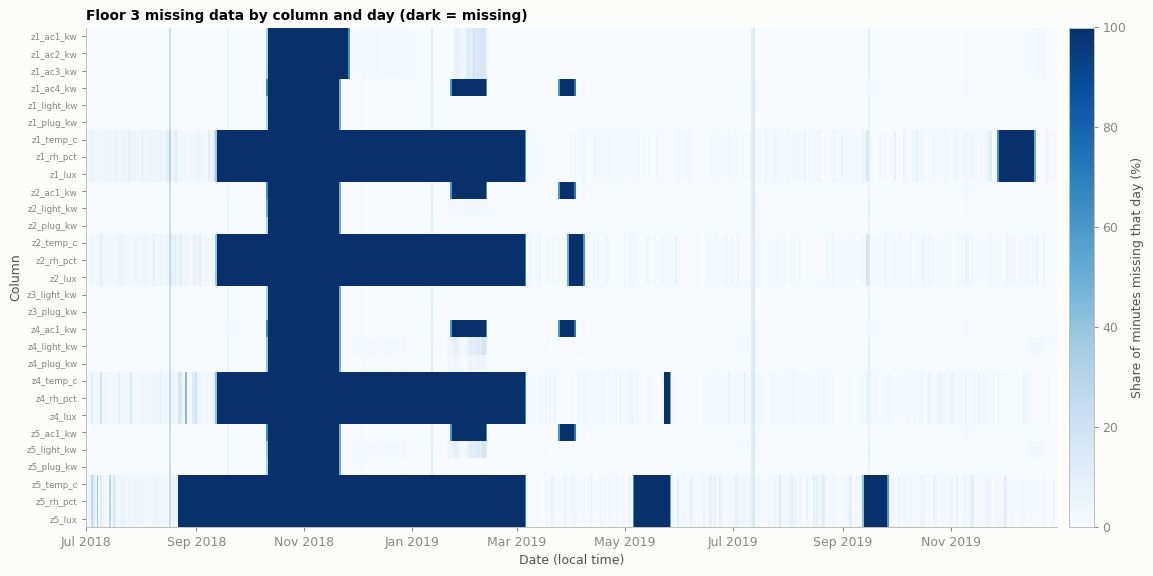

In [7]:
na = floor.isna()
longest_gap_h = {c: (run_lengths(na[c])['length'].max() if na[c].any() else 0) / 60 for c in floor.columns}
missing_table = pd.DataFrame({
    'missing_%_all': na.mean() * 100,
    'missing_%_2018': na[floor.index.year == 2018].mean() * 100,
    'missing_%_2019': na[floor.index.year == 2019].mean() * 100,
    'longest_gap_h': pd.Series(longest_gap_h),
}).round(1)
print('Five columns with the most missing data:')
display(missing_table.sort_values('missing_%_all', ascending=False).head(5))
print('Median across columns:', missing_table.median().round(1).to_dict())

daily_missing = na.resample('D').mean().mul(100)
fig, ax = plt.subplots(figsize=(14, 6.5))
im = ax.imshow(daily_missing.T.to_numpy(), aspect='auto', cmap='Blues', vmin=0, vmax=100, interpolation='nearest',
               extent=[mdates.date2num(daily_missing.index[0]), mdates.date2num(daily_missing.index[-1]),
                       len(floor.columns) - 0.5, -0.5])
ax.set_yticks(range(len(floor.columns)), floor.columns, fontsize=7)
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(False)
fig.colorbar(im, ax=ax, label='Share of minutes missing that day (%)', pad=0.01)
label_axes(ax, 'Floor 3 missing data by column and day (dark = missing)', 'Date (local time)', 'Column', legend=False)
plt.tight_layout()
plt.show()

In [8]:
def gap_bucket_counts(mask):
    runs = run_lengths(mask)
    bins = [0, 5, 60, 24 * 60, np.inf]
    labels = ['<=5 min', '5-60 min', '1-24 h', '>24 h']
    return pd.cut(runs['length'], bins=bins, labels=labels).value_counts().reindex(labels)


gap_buckets = pd.DataFrame({c: gap_bucket_counts(na[c]) for c in floor.columns}).T
gap_buckets['group'] = col_map.set_index('tidy').loc[gap_buckets.index, 'quantity']
print('Number of NaN runs (gaps) by length, summed per quantity group:')
display(gap_buckets.groupby('group').sum())

Number of NaN runs (gaps) by length, summed per quantity group:


length,<=5 min,5-60 min,1-24 h,>24 h
group,,,,
humidity,6185,1106,59,9
illuminance,6184,1106,59,9
power,11407,1129,73,27
temperature,6179,1106,59,9


**Reading the missing-data picture**
- **Sep 2018 – early Mar 2019:** all temperature, humidity and lux sensors are essentially offline. **Any analysis that uses temperature or lux is therefore limited to Jul–Aug 2018 and Mar–Dec 2019.**
- **Oct–Nov 2018:** most power meters are missing for about 6 weeks. The CU-BEMS descriptor attributes gaps like this to IT reconfigurations that cut the floor gateways off the network.
- **Jan–Feb and late Mar 2019:** the four large-AC digital meters (`z1_ac4`, `z2/z4/z5_ac1`) drop out together while the other meters keep reporting. This means the large-AC meters sit on a separate communication path.
- Most other gaps last 5 minutes or less. These are safe to interpolate.

### 4.3 Physically impossible values

In [9]:
lo_t, hi_t = CFG['temp_range_c']
lo_rh, hi_rh = CFG['rh_range_pct']
lo_lx, hi_lx = CFG['lux_range']
impossible = {
    'negative_kw': floor[POWER_COLS] < 0,
    'temp_out_of_range': (floor[TEMP_COLS] < lo_t) | (floor[TEMP_COLS] > hi_t),
    'rh_out_of_range': (floor[RH_COLS] < lo_rh) | (floor[RH_COLS] > hi_rh),
    'lux_out_of_range': (floor[LUX_COLS] < lo_lx) | (floor[LUX_COLS] > hi_lx),
}
impossible_counts = pd.Series({k: int(v.to_numpy().sum()) for k, v in impossible.items()}, name='values')
display(impossible_counts.to_frame())
print('Observed ranges -> temperature', floor[TEMP_COLS].min().min(), '-', floor[TEMP_COLS].max().max(), 'degC;',
      'RH', floor[RH_COLS].min().min(), '-', floor[RH_COLS].max().max(), '%;',
      'lux', floor[LUX_COLS].min().min(), '-', floor[LUX_COLS].max().max())

,values
negative_kw,0
temp_out_of_range,0
rh_out_of_range,0
lux_out_of_range,0


Observed ranges -> temperature 15.73 - 30.9 degC; RH 45.71 - 93.67 %; lux 0.0 - 90.0


No value breaks a hard physical limit. Temperatures of 15.7 to 30.9 °C are plausible indoors, although readings below 20 °C while the AC is running are themselves a candidate anomaly (7c). The lux sensors never read above about 90 lux, far below daylight levels. Section 7d shows that these sensors mostly see the lamps rather than daylight.

### 4.4 Power spikes (likely backfill artefacts)
The range checks miss one real problem: short **kW spikes** that are 10 to 40 times the normal level (for example `z2_light_kw` at 236 kW against a normal ~6 kW). They almost always occur **immediately after a communication gap**. According to the CU-BEMS descriptor, the meters store data locally during an outage and re-send it afterwards, so these spikes are treated as backfill artefacts rather than real load.

Spike rule: kW > 1.25 x column P99.99. Total spike minutes: 490 (99% within 5 min of a data gap)


,cap_kw,normal_p99_kw,max_kw,spike_minutes,within_5min_of_a_gap
z2_light_kw,16.110,6.670,236.200,36,34
z4_light_kw,11.200,3.080,186.100,49,49
z5_light_kw,8.770,2.760,172.300,41,41
z1_light_kw,16.400,5.800,162.200,45,44
z5_plug_kw,3.080,0.960,68.800,55,55
z2_ac1_kw,35.990,26.460,59.100,12,12


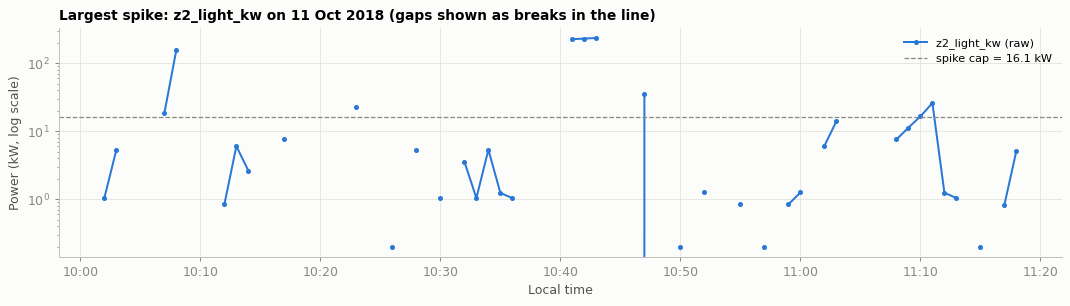

In [10]:
caps = floor[POWER_COLS].quantile(0.9999) * CFG['spike_factor_p9999']
spikes = floor[POWER_COLS].gt(caps)
recent_gap = na[POWER_COLS].any(axis=1).astype('int8').rolling(6, min_periods=1).max().astype(bool)   # a power-meter gap within 5 min
spike_table = pd.DataFrame({
    'cap_kw': caps.round(2),
    'normal_p99_kw': floor[POWER_COLS].quantile(0.99).round(2),
    'max_kw': floor[POWER_COLS].max().round(1),
    'spike_minutes': spikes.sum(),
    'within_5min_of_a_gap': spikes.loc[recent_gap].sum(),
})
print(f"Spike rule: kW > {CFG['spike_factor_p9999']} x column P99.99. Total spike minutes: {int(spike_table.spike_minutes.sum())} "
      f"({spike_table.within_5min_of_a_gap.sum() / spike_table.spike_minutes.sum():.0%} within 5 min of a data gap)")
display(spike_table.sort_values('max_kw', ascending=False).head(6))

# Show the largest spike in context.
worst_col = spike_table['max_kw'].idxmax()
t0 = floor[worst_col].idxmax()
window = floor.loc[t0 - pd.Timedelta('45min'): t0 + pd.Timedelta('45min'), worst_col]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(window.index, window, marker='o', markersize=3, label=f'{worst_col} (raw)')
ax.axhline(caps[worst_col], color=MUTED, linestyle='--', linewidth=1, label=f'spike cap = {caps[worst_col]:.1f} kW')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ))
label_axes(ax, f'Largest spike: {worst_col} on {t0:%d %b %Y} (gaps shown as breaks in the line)',
           'Local time', 'Power (kW, log scale)')
plt.tight_layout()
plt.show()

### 4.5 Flat-lined / stuck sensors
Temperature and RH naturally fluctuate at a resolution of 0.01, so a long run of one identical value suggests a stuck sensor. For kW circuits a constant value is **normal**: lamps draw constant power, and AC units sit at a fixed standby draw (for example `z1_ac4` at ~0.07 kW overnight). Lux reads 0 all night. The stuck-value test is therefore applied only to temperature and RH.

In [11]:
def constant_run_lengths(series):
    """Length (in rows) of the run of identical consecutive values each row belongs to (NaN rows -> NaN)."""
    run_id = (series.ne(series.shift()) | series.isna()).cumsum()
    return series.groupby(run_id).transform('size').where(series.notna())


stuck_cols = TEMP_COLS + RH_COLS
run_len = pd.DataFrame({c: constant_run_lengths(floor[c]) for c in stuck_cols})
stuck = run_len >= CFG['stuck_min_minutes']
stuck_table = pd.DataFrame({'longest_constant_run_min': run_len.max(), 'stuck_minutes': stuck.sum()})
display(stuck_table.T)
print(f"No temperature/RH sensor stays constant for >= {CFG['stuck_min_minutes']} min"
      if stuck.to_numpy().sum() == 0 else f"{int(stuck.to_numpy().sum())} stuck minutes flagged")
del run_len

,z1_temp_c,z2_temp_c,z4_temp_c,z5_temp_c,z1_rh_pct,z2_rh_pct,z4_rh_pct,z5_rh_pct
longest_constant_run_min,57.000,53.000,47.000,61.000,23.000,23.000,20.000,24.000
stuck_minutes,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


No temperature/RH sensor stays constant for >= 120 min


### 4.6 Which analyses are possible in which months

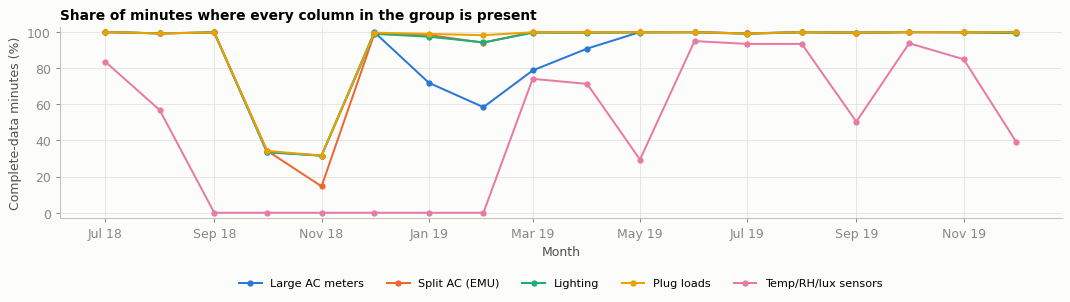

In [12]:
groups = {
    'Large AC meters': LARGE_AC, 'Split AC (EMU)': SPLIT_AC,
    'Lighting': col_map.loc[col_map.end_use == 'Light', 'tidy'].tolist(),
    'Plug loads': col_map.loc[col_map.end_use == 'Plug', 'tidy'].tolist(),
    'Temp/RH/lux sensors': ENV_COLS,
}
coverage_month = pd.DataFrame({g: floor[cols].notna().all(axis=1).resample('MS').mean() * 100 for g, cols in groups.items()})
fig, ax = plt.subplots(figsize=(12, 3.8))
for g in coverage_month:
    ax.plot(coverage_month.index, coverage_month[g], marker='o', markersize=4, label=g)
ax.set_ylim(-3, 103)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
label_axes(ax, 'Share of minutes where every column in the group is present', 'Month', 'Complete-data minutes (%)')
ax.legend(ncol=5, loc='lower center', bbox_to_anchor=(0.5, -0.42))
plt.tight_layout()
plt.show()

### 4.7 Cleaning decisions and cleaning log
The cleaning is applied in the order below, to a copy of the data (`clean`). Every step is counted.

In [13]:
clean = floor.copy()
log = []


def log_step(issue, columns, rule, n_values, decision, rationale):
    log.append(dict(issue=issue, columns=columns, rule=rule, values_affected=int(n_values),
                    decision=decision, rationale=rationale))


log_step('Duplicate timestamps', 'Date', 'Date.duplicated()', file_audit.duplicate_timestamps.sum(),
         'drop (keep first)', 'None present; the rule is kept for reproducibility')
log_step('Out-of-order rows', 'Date', 'negative time step', file_audit.out_of_order_rows.sum(),
         'sort by time', 'None present')
log_step('Missing timestamps', 'Date', 'compare with full 1-min grid', ts_checks.missing_timestamps.sum(),
         'none needed', 'The grid is complete; missing data appears as NaN values')
for key, cols, rule in [('negative_kw', 'kW columns', 'kW < 0'),
                        ('temp_out_of_range', 'temperature', f'outside {CFG["temp_range_c"]} degC'),
                        ('rh_out_of_range', 'humidity', f'outside {CFG["rh_range_pct"]} %'),
                        ('lux_out_of_range', 'lux', f'outside {CFG["lux_range"]} lux')]:
    mask = impossible[key]
    clean[mask.columns] = clean[mask.columns].mask(mask)
    log_step(key.replace('_', ' ').capitalize(), cols, rule, mask.to_numpy().sum(), 'set to NaN', 'Physically impossible')

clean[POWER_COLS] = clean[POWER_COLS].mask(spikes)
log_step('kW spikes', 'kW columns', f"> {CFG['spike_factor_p9999']} x column P99.99", spikes.to_numpy().sum(),
         'set to NaN (flagged as data-quality anomaly)',
         f"{spike_table.within_5min_of_a_gap.sum() / max(spike_table.spike_minutes.sum(), 1):.0%} follow a comms gap: consistent with meter backfill")

clean[stuck_cols] = clean[stuck_cols].mask(stuck)
log_step('Stuck temperature/RH', 'temperature, humidity', f">= {CFG['stuck_min_minutes']} min constant",
         stuck.to_numpy().sum(), 'set to NaN', 'A constant value that long is not physical for these sensors')

na_before = clean.isna().to_numpy().sum()
for c in clean.columns:
    clean[c] = interpolate_short_gaps(clean[c], CFG['short_gap_max_min'])
na_after = clean.isna().to_numpy().sum()
log_step('Short gaps', 'all', f"NaN runs <= {CFG['short_gap_max_min']} min between valid values", na_before - na_after,
         'linear interpolation', 'A few minutes of missing data barely changes energy or temperature')
log_step('Long gaps', 'all', f"NaN runs > {CFG['short_gap_max_min']} min", na_after,
         'leave NaN; exclude intervals with < 80% coverage', 'Filling hours or weeks would invent data')
clean = clean.astype('float32')

cleaning_log = pd.DataFrame(log)
display(cleaning_log)

,issue,columns,rule,values_affected,decision,rationale
0,Duplicate timestamps,Date,Date.duplicated(),0,drop (keep first),None present; the rule is kept for reproducibi...
1,Out-of-order rows,Date,negative time step,0,sort by time,None present
2,Missing timestamps,Date,compare with full 1-min grid,0,none needed,The grid is complete; missing data appears as ...
3,Negative kw,kW columns,kW < 0,0,set to NaN,Physically impossible
4,Temp out of range,temperature,"outside (10.0, 40.0) degC",0,set to NaN,Physically impossible
5,Rh out of range,humidity,"outside (0.0, 100.0) %",0,set to NaN,Physically impossible
6,Lux out of range,lux,"outside (0.0, 2000.0) lux",0,set to NaN,Physically impossible
7,kW spikes,kW columns,> 1.25 x column P99.99,490,set to NaN (flagged as data-quality anomaly),99% follow a comms gap: consistent with meter ...
8,Stuck temperature/RH,"temperature, humidity",>= 120 min constant,0,set to NaN,A constant value that long is not physical for...
9,Short gaps,all,NaN runs <= 5 min between valid values,55450,linear interpolation,A few minutes of missing data barely changes e...


In [14]:
# Data-quality anomaly records (Section 7 category 1): long gaps (>= 60 min) and spikes.
gap_rows = []
for c in floor.columns:
    runs = run_lengths(floor[c].isna())
    runs = runs[runs['length'] >= 60]
    gap_rows.append(runs.assign(column=c)[['start', 'end', 'length', 'column']])
gap_rows = pd.concat(gap_rows)
zone_of = col_map.set_index('tidy')['zone']
# Merge identical outages across columns into one record.
gap_events = (gap_rows.groupby(['start', 'end', 'length'])['column']
              .agg(lambda cols: sorted(cols)).reset_index())
gap_events['zone'] = gap_events['column'].map(lambda cols: 'floor' if len({zone_of[c] for c in cols}) == len(ZONES) and len(cols) > 20
                                               else ','.join(sorted({zone_of[c] for c in cols})))
gap_events['variable'] = gap_events['column'].map(lambda cols: ','.join(cols) if len(cols) <= 3 else f'{len(cols)} columns')
dq_gaps = to_records(gap_events.assign(timestamp_start=gap_events.start,
                                       timestamp_end=gap_events.end + pd.Timedelta('1min'),
                                       magnitude=(gap_events.length / 60).round(2)),
                     anomaly_type='data_quality/gap_ge_60min',
                     rule_used='NaN run >= 60 min (magnitude = gap length in hours)')

spike_events = []
for c in POWER_COLS:
    frame = pd.DataFrame({'flag': spikes[c], 'kw': floor[c]})
    ev = flagged_events(frame, 'flag', '1min', peak_kw=('kw', 'max'))
    if not ev.empty:
        spike_events.append(ev.assign(zone=zone_of[c], variable=c, magnitude=ev.peak_kw.round(2)))
dq_spikes = to_records(pd.concat(spike_events), anomaly_type='data_quality/power_spike',
                       rule_used=f"kW > {CFG['spike_factor_p9999']} x column P99.99 (magnitude = peak kW; removed)")
dq_anomalies = pd.concat([dq_gaps, dq_spikes], ignore_index=True)
print(f'Data-quality anomalies: {len(dq_gaps)} gap events (>= 60 min), {len(dq_spikes)} spike events')
del na, spikes, stuck, impossible

Data-quality anomalies: 109 gap events (>= 60 min), 344 spike events


## 5. Resampling, calendar and external context

**Energy conversion.** Each 1-minute reading is average power in kW over that minute, so the energy in that minute is `kW × 1/60` kWh. Over an interval with complete data, `Σ(kW × 1/60)` equals `mean(kW) × interval hours`. We use the mean form so that intervals with a few interpolated or missing minutes are not biased low. An interval is kept only when at least 80% of its minutes are valid.

In [15]:
def resample_floor(frame, rule, min_coverage):
    """Resample 1-min data: kW -> kWh per interval, sensors -> mean. Intervals below min_coverage become NaN."""
    minutes = pd.Timedelta(rule) / pd.Timedelta('1min')
    grouped = frame.resample(rule)
    means = grouped.mean()
    enough = grouped.count() >= min_coverage * minutes
    means = means.where(enough)
    energy = (means[POWER_COLS] * (minutes / 60)).rename(columns=lambda c: c.replace('_kw', '_kwh'))
    return pd.concat([energy, means[ENV_COLS]], axis=1).astype('float32')


# Check the conversion on the first complete hour of data.
hour0 = clean[POWER_COLS].resample('1h').count().eq(60).all(axis=1).idxmax()
block = clean.loc[hour0: hour0 + pd.Timedelta('59min'), POWER_COLS]
assert np.allclose((block / 60).sum(), block.mean() * 1.0, atol=1e-4)
print('kWh check passed: sum(kW/60) == mean(kW) x 1 h for', hour0)

q15 = resample_floor(clean, '15min', CFG['min_coverage'])
hourly = resample_floor(clean, '1h', CFG['min_coverage'])
KWH_COLS = [c.replace('_kw', '_kwh') for c in POWER_COLS]
ZONE_ENDUSE = {(z, e): [c.replace('_kw', '_kwh') for c in g.tidy]
               for (z, e), g in col_map[col_map.quantity == 'power'].groupby(['zone', 'end_use'])}


def add_totals(frame):
    """Zone-level and floor-level end-use totals. A total is NaN unless every component is present (fair comparison)."""
    for (zone, end_use), cols in ZONE_ENDUSE.items():
        frame[f'{zone}_{end_use.lower()}_total_kwh'] = frame[cols].sum(axis=1, min_count=len(cols))
    for end_use in ['AC', 'Light', 'Plug']:
        cols = [c for (z, e), cs in ZONE_ENDUSE.items() if e == end_use for c in cs]
        frame[f'floor_{end_use.lower()}_kwh'] = frame[cols].sum(axis=1, min_count=len(cols))
    frame['floor_total_kwh'] = frame[['floor_ac_kwh', 'floor_light_kwh', 'floor_plug_kwh']].sum(axis=1, min_count=3)
    return frame


q15, hourly = add_totals(q15), add_totals(hourly)
print(f'15-min: {q15.shape}, hourly: {hourly.shape}; hours with a complete floor total: {hourly.floor_total_kwh.notna().mean():.1%}')

kWh check passed: sum(kW/60) == mean(kW) x 1 h for 2018-07-01 00:00:00+07:00
15-min: (52704, 47), hourly: (13176, 47); hours with a complete floor total: 86.0%


### 5.1 Thai public holidays (external data)
**Source:** the `holidays` Python package (vacanza/holidays), `country_holidays('TH', categories=['public', 'government'])`. It includes in-lieu (substitution) days and the Royal Ploughing Ceremony, when government offices close. A copy is cached to `data/external/thai_holidays_2018_2019.csv`.

In [16]:
HOLIDAY_CACHE = EXTERNAL_DIR / 'thai_holidays_2018_2019.csv'


def load_thai_holidays(years):
    if holidays is not None:
        cal = holidays.country_holidays('TH', years=list(years), language='en_US', categories=['public', 'government'])
        table = pd.DataFrame(sorted(cal.items()), columns=['date', 'holiday_name'])
        table.to_csv(HOLIDAY_CACHE, index=False)
        source = f'holidays package v{holidays.__version__}'
    elif HOLIDAY_CACHE.exists():
        table, source = pd.read_csv(HOLIDAY_CACHE), f'cached {HOLIDAY_CACHE.name}'
    else:
        raise ImportError('pip install holidays (or restore data/external/thai_holidays_2018_2019.csv)')
    table['date'] = pd.to_datetime(table['date']).dt.tz_localize(TZ)
    return table, source


holiday_table, holiday_source = load_thai_holidays(YEARS)
holiday_table = holiday_table[holiday_table.date >= floor.index.min().normalize()]
HOLIDAY_NAMES = holiday_table.set_index('date')['holiday_name']
print(f'{len(holiday_table)} holidays in the data window ({holiday_source}); '
      f'{(holiday_table.date.dt.dayofweek < 5).sum()} fall on weekdays')

37 holidays in the data window (holidays package v0.105); 27 fall on weekdays


### 5.2 Outdoor weather (external data)
**Source:** Open-Meteo Historical Weather API (ERA5 reanalysis), hourly `temperature_2m`, `relative_humidity_2m`, `dew_point_2m`, `shortwave_radiation` and `cloud_cover` at 13.738 N, 100.531 E. Citation: Zippenfeld, P. (2023). *Open-Meteo.com Weather API* [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.7970649; Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Q. J. R. Meteorol. Soc.* 146, 1999–2049. Data licence CC BY 4.0.

**Timezone:** the file was requested in **UTC** and is converted to Asia/Bangkok (UTC+7) here. The check below confirms that peak solar radiation lands around local noon. ERA5 is a ~25 km grid, so it describes the Bangkok area, not the building roof.

In [17]:
WEATHER_CACHE = EXTERNAL_DIR / 'openmeteo_bangkok_hourly_2018-06-30_2019-12-31_UTC.csv'
WEATHER_URL = ('https://archive-api.open-meteo.com/v1/archive?latitude=13.738&longitude=100.531'
               '&start_date=2018-06-30&end_date=2019-12-31'
               '&hourly=temperature_2m,relative_humidity_2m,dew_point_2m,shortwave_radiation,cloud_cover'
               '&timezone=GMT&format=csv')
WEATHER_RENAME = {'temperature_2m': 'out_temp_c', 'relative_humidity_2m': 'out_rh_pct', 'dew_point_2m': 'out_dewpoint_c',
                  'shortwave_radiation': 'solar_wm2', 'cloud_cover': 'cloud_pct'}


def load_weather():
    if not WEATHER_CACHE.exists():
        if requests is None:
            raise ImportError('requests is needed to download the weather file; see Section 10 for manual steps')
        response = requests.get(WEATHER_URL, timeout=60)
        response.raise_for_status()
        WEATHER_CACHE.write_bytes(response.content)
    w = pd.read_csv(WEATHER_CACHE, skiprows=3)
    w.columns = [WEATHER_RENAME.get(c.split(' ')[0], c) for c in w.columns]
    w['time'] = pd.to_datetime(w['time']).dt.tz_localize('UTC').dt.tz_convert(TZ)
    w = w.set_index('time').astype('float32')
    # Open-Meteo radiation is the mean over the PRECEDING hour (label = hour end). Our hourly index labels the hour start,
    # so shift radiation back one hour. Temperature, RH, dew point and cloud cover are instantaneous and stay as they are.
    w['solar_wm2'] = w['solar_wm2'].shift(-1)
    return w


weather = load_weather()
peak_solar_hour = weather.groupby(weather.index.hour)['solar_wm2'].mean().idxmax()
print(f'Weather: {len(weather):,} hourly rows; after conversion, mean solar radiation peaks in the hour starting '
      f'{peak_solar_hour}:00 local time (solar noon in Bangkok is ~12:00-12:30, so 11 or 12 confirms the UTC->UTC+7 shift).')
hourly = hourly.join(weather, how='left')

Weather: 13,200 hourly rows; after conversion, mean solar radiation peaks in the hour starting 11:00 local time (solar noon in Bangkok is ~12:00-12:30, so 11 or 12 confirms the UTC->UTC+7 shift).


### 5.3 Sunrise / sunset (computed, no download)
Computed with the `astral` package for the building's coordinates, then used to separate daylight from night in the lighting analysis.

In [18]:
def daylight_table(dates):
    observer = Observer(latitude=SITE_LAT, longitude=SITE_LON, elevation=0)
    rows = []
    for d in dates:
        times = sun(observer, date=d.date(), tzinfo=TZ)
        rows.append({'date': d, 'sunrise': pd.Timestamp(times['sunrise']), 'sunset': pd.Timestamp(times['sunset'])})
    return pd.DataFrame(rows).set_index('date')


if sun is None:
    raise ImportError('pip install astral (used for sunrise/sunset)')
sun_times = daylight_table(pd.date_range(floor.index.min().normalize(), floor.index.max().normalize(), freq='D'))
day_len = (sun_times.sunset - sun_times.sunrise).dt.total_seconds() / 3600
print(f'Sunrise {sun_times.sunrise.dt.strftime("%H:%M").min()}-{sun_times.sunrise.dt.strftime("%H:%M").max()}, '
      f'sunset {sun_times.sunset.dt.strftime("%H:%M").min()}-{sun_times.sunset.dt.strftime("%H:%M").max()}, '
      f'day length {day_len.min():.1f}-{day_len.max():.1f} h')

Sunrise 05:49-06:45, sunset 17:46-18:49, day length 11.3-12.9 h


### 5.4 Chulalongkorn academic calendar (context only)
**Source:** Chulalongkorn University, *Chulalongkorn University Academic Calendar 2019*, https://www.chula.ac.th/en/news/18302/. Only academic year 2019, semester 1 (classes 13 Aug – 29 Nov 2019, finals 2–17 Dec 2019) could be verified online; 2018 dates are not in `data/external/chula_academic_calendar.csv` yet (see Section 10 for how to add them). It is used **only to shade charts**, never as an occupancy measure.

In [19]:
academic = pd.read_csv(EXTERNAL_DIR / 'chula_academic_calendar.csv', parse_dates=['start_date', 'end_date'])
for col in ['start_date', 'end_date']:
    academic[col] = academic[col].dt.tz_localize(TZ)
print(academic[['academic_year', 'term', 'start_date', 'end_date', 'event']].to_string(index=False))

 academic_year       term                start_date                  end_date                                      event
          2019 Semester 1 2019-08-13 00:00:00+07:00 2019-11-29 00:00:00+07:00 Classes (first day to last day of classes)
          2019 Semester 1 2019-12-02 00:00:00+07:00 2019-12-17 00:00:00+07:00                         Final examinations


### 5.5 Calendar features
The base day types are *workday*, *weekend* and *holiday*. Section 6.4 adds *closure* for weekdays with near-zero load that are not on the holiday list.

In [20]:
def add_calendar(frame):
    idx = frame.index
    frame['date'] = idx.normalize()
    frame['hour'] = idx.hour.astype('int8')
    frame['slot'] = (idx.hour * 4 + idx.minute // 15).astype('int16')
    frame['weekday'] = idx.dayofweek.astype('int8')
    frame['is_weekend'] = frame['weekday'] >= 5
    frame['month'] = idx.month.astype('int8')
    frame['year'] = idx.year.astype('int16')
    frame['holiday_name'] = frame['date'].map(HOLIDAY_NAMES)
    frame['is_holiday'] = frame['holiday_name'].notna()
    frame['day_type'] = np.select([frame.is_holiday, frame.is_weekend], ['holiday', 'weekend'], 'workday')
    return frame


q15, hourly = add_calendar(q15), add_calendar(hourly)
display(hourly.drop_duplicates('date').day_type.value_counts().rename('days').to_frame().T)

day_type,workday,weekend,holiday
days,365,147,37


## 6. Baseline: what "normal" looks like

### 6.1 Typical load profiles by end-use and day type
The median is used rather than the mean because the loads are strongly bimodal (on/off). The shaded band shows the working-day interquartile range.

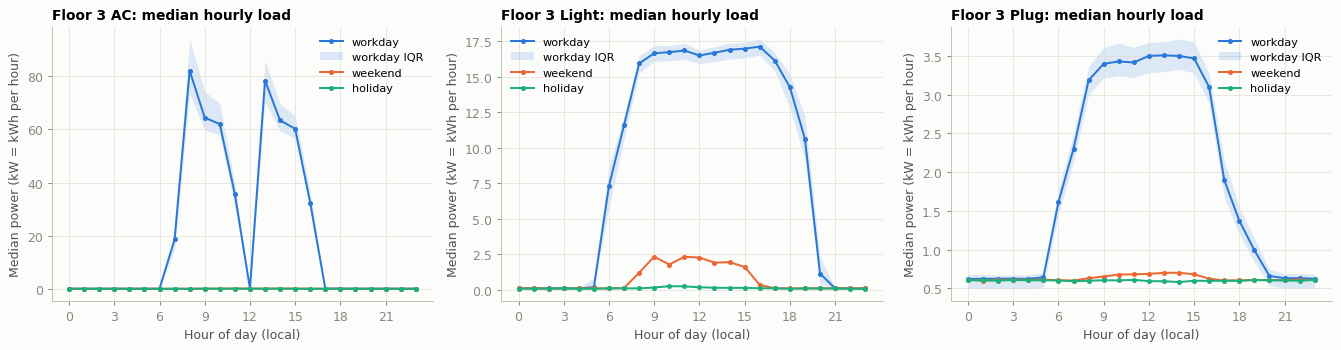

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, end_use in zip(axes, ['AC', 'Light', 'Plug']):
    col = f'floor_{end_use.lower()}_kwh'
    stats = hourly.groupby(['day_type', 'hour'])[col].quantile([0.25, 0.5, 0.75]).unstack()
    for i, day_type in enumerate(['workday', 'weekend', 'holiday']):
        s = stats.loc[day_type]
        ax.plot(s.index, s[0.5], color=PALETTE[i], marker='o', markersize=3, label=day_type)
        if day_type == 'workday':
            ax.fill_between(s.index, s[0.25], s[0.75], color=PALETTE[i], alpha=0.15, linewidth=0, label='workday IQR')
    ax.set_xticks(range(0, 24, 3))
    label_axes(ax, f'Floor 3 {end_use}: median hourly load', 'Hour of day (local)', 'Median power (kW = kWh per hour)')
plt.tight_layout()
plt.show()

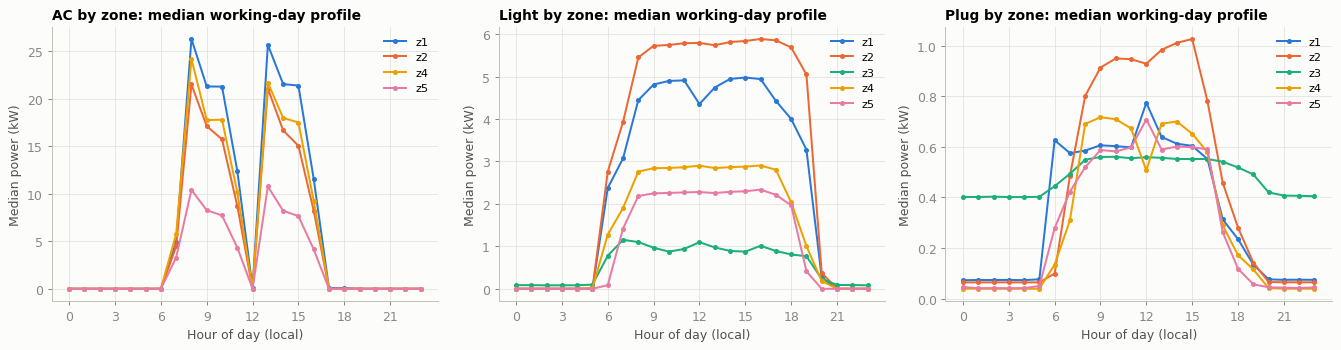

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
work = hourly[hourly.day_type == 'workday']
for ax, end_use in zip(axes, ['AC', 'Light', 'Plug']):
    for i, zone in enumerate(ZONES):
        col = f'{zone}_{end_use.lower()}_total_kwh'
        if col in work:
            prof = work.groupby('hour')[col].median()
            ax.plot(prof.index, prof, color=PALETTE[i], marker='o', markersize=3, label=zone)
    ax.set_xticks(range(0, 24, 3))
    label_axes(ax, f'{end_use} by zone: median working-day profile', 'Hour of day (local)', 'Median power (kW)')
plt.tight_layout()
plt.show()

**What the profiles show**
- **AC follows a rigid central schedule.** On working days the large compressors start at about 07:30, switch off for lunch around 11:30–13:00, restart at 13:00 and stop at about 16:30. The 08:00 and 13:00 peaks in the old notebook are the two start-up pull-downs. The AC is almost never on at weekends or on holidays.
- Lighting and plug loads have a wider daytime plateau. Zone 3 (staircase) lighting draws a small, near-constant load.

### 6.2 Empirically derived operating hours
For each working day and each circuit, "on" means load above `baseload + 30% × (daily P95 − baseload)`, where baseload is the day's 01:00–05:00 median. The circuit's operating window is the median first-on to last-off time across working days. Circuits that rarely operate (for example the small split AC units) fall back to their floor-level end-use window.

In [23]:
def daily_grid(series):
    """15-min series -> (days x 96 slots) array, plus its day index."""
    frame = pd.DataFrame({'v': series.to_numpy(dtype=float), 'date': series.index.normalize(),
                          'slot': series.index.hour * 4 + series.index.minute // 15})
    grid = frame.pivot_table(index='date', columns='slot', values='v', aggfunc='first').reindex(columns=range(SLOTS_PER_DAY))
    return grid.to_numpy(), grid.index


def daily_on_window(series_kw, on_frac, min_range_kw):
    """Per day: night baseload, P95, first-on and last-off slot."""
    arr, days = daily_grid(series_kw)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        base = np.nanmedian(arr[:, NIGHT_BASELOAD_HOURS[0] * 4: NIGHT_BASELOAD_HOURS[1] * 4], axis=1)
        peak = np.nanpercentile(arr, 95, axis=1)
    on = arr > (base + on_frac * (peak - base))[:, None]
    operated = ((peak - base) >= min_range_kw) & on.any(axis=1)
    first = np.where(operated, on.argmax(axis=1), np.nan)
    last = np.where(operated, SLOTS_PER_DAY - on[:, ::-1].argmax(axis=1), np.nan)
    valid = np.isfinite(arr).sum(axis=1) >= CFG['min_coverage'] * SLOTS_PER_DAY
    return pd.DataFrame({'base_kw': base, 'p95_kw': peak, 'start_slot': first, 'end_slot': last,
                         'operated': operated, 'valid': valid}, index=days)


workdays = pd.DatetimeIndex(q15.loc[q15.day_type == 'workday', 'date'].unique())
MIN_RANGE_KW = {'AC': 1.0, 'Light': 0.2, 'Plug': 0.1}


def circuit_windows(kwh_cols, end_use_of):
    rows = {}
    for col in kwh_cols:
        daily = daily_on_window(q15[col] * 4, CFG['schedule_on_frac'], MIN_RANGE_KW[end_use_of(col)])
        wd = daily[daily.index.isin(workdays) & daily.valid]
        rows[col] = {'end_use': end_use_of(col), 'operated_share': wd.operated.mean(),
                     'start_slot': wd.loc[wd.operated, 'start_slot'].median(),
                     'end_slot': wd.loc[wd.operated, 'end_slot'].median(),
                     'start_iqr_h': (wd.start_slot.quantile(0.75) - wd.start_slot.quantile(0.25)) / 4}
    return pd.DataFrame(rows).T


end_use_of = lambda c: 'AC' if '_ac' in c else ('Light' if 'light' in c else 'Plug')
floor_windows = circuit_windows(['floor_ac_kwh', 'floor_light_kwh', 'floor_plug_kwh', 'floor_total_kwh'],
                                lambda c: {'floor_light_kwh': 'Light', 'floor_plug_kwh': 'Plug'}.get(c, 'AC'))
windows = circuit_windows(KWH_COLS, end_use_of)
# DECISION: circuits operating on < 50% of working days use their floor-level end-use window.
for col in windows.index[windows.operated_share < 0.5]:
    fallback = floor_windows.loc[f"floor_{windows.at[col, 'end_use'].lower()}_kwh"]
    windows.loc[col, ['start_slot', 'end_slot']] = fallback[['start_slot', 'end_slot']].to_numpy()
    windows.loc[col, 'end_use'] = windows.at[col, 'end_use'] + ' (floor window)'

show = pd.concat([floor_windows, windows])
show['window'] = show.start_slot.map(slot_to_time) + '–' + show.end_slot.map(slot_to_time)
display(show[['end_use', 'operated_share', 'window', 'start_iqr_h']].astype({'operated_share': float}).round(2))
OPERATING_WINDOW = (floor_windows.at['floor_total_kwh', 'start_slot'], floor_windows.at['floor_total_kwh', 'end_slot'])
print('Derived floor operating window (total load):', ' - '.join(slot_to_time(s) for s in OPERATING_WINDOW),
      f'(nominal assumption was {NOMINAL_OPEN_HOUR:02d}:00-{NOMINAL_CLOSE_HOUR:02d}:00)')

,end_use,operated_share,window,start_iqr_h
floor_ac_kwh,AC,1.000,07:45–16:30,0.000
floor_light_kwh,Light,0.990,06:15–20:00,0.250
floor_plug_kwh,Plug,0.990,06:15–18:15,0.250
floor_total_kwh,AC,1.000,07:45–16:45,0.000
z1_ac1_kwh,AC (floor window),0.000,07:45–16:30,0.000
z1_ac2_kwh,AC (floor window),0.020,07:45–16:30,1.438
z1_ac3_kwh,AC (floor window),0.000,07:45–16:30,0.000
z1_ac4_kwh,AC,0.990,07:45–16:30,0.000
z1_light_kwh,Light,0.990,06:15–20:00,0.250
z1_plug_kwh,Plug,0.990,06:15–18:30,0.250


Derived floor operating window (total load): 07:45 - 16:45 (nominal assumption was 08:00-17:00)


### 6.3 Night-time baseload
The baseload is the 01:00–05:00 median power of each circuit, tracked with a trailing 28-day median so that slow drift (for example new always-on equipment) is followed. It feeds the after-hours analysis (7a).

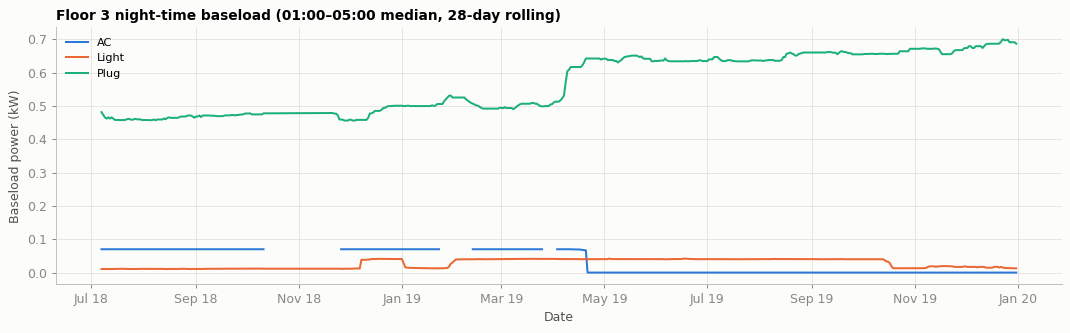

Median night baseload (kW): {'floor_ac_kwh': 0.0, 'floor_light_kwh': 0.04, 'floor_plug_kwh': 0.63}
Plug baseload drift: 0.46 kW (first 60 days) -> 0.67 kW (last 60 days), +0.21 kW = ~1,858 kWh/year if it runs 24/7 (candidate: new always-on equipment).


In [24]:
def night_baseload_kw(kwh_col):
    """Trailing 28-day median of each day's 01:00-05:00 median power (kW), indexed by date."""
    arr, days = daily_grid(q15[kwh_col] * 4)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        nightly = pd.Series(np.nanmedian(arr[:, NIGHT_BASELOAD_HOURS[0] * 4: NIGHT_BASELOAD_HOURS[1] * 4], axis=1), index=days)
    return nightly.rolling(CFG['baseload_roll_days'], min_periods=7).median()


baseload = pd.DataFrame({c: night_baseload_kw(c) for c in KWH_COLS + ['floor_ac_kwh', 'floor_light_kwh', 'floor_plug_kwh']})
fig, ax = plt.subplots(figsize=(12, 3.8))
for end_use in ['AC', 'Light', 'Plug']:
    ax.plot(baseload.index, baseload[f'floor_{end_use.lower()}_kwh'], color=END_USE_COLOURS[end_use], label=end_use)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
label_axes(ax, 'Floor 3 night-time baseload (01:00–05:00 median, 28-day rolling)', 'Date', 'Baseload power (kW)')
plt.tight_layout()
plt.show()
print('Median night baseload (kW):', baseload[['floor_ac_kwh', 'floor_light_kwh', 'floor_plug_kwh']].median().round(2).to_dict())
plug_base = baseload['floor_plug_kwh'].dropna()
creep_kw = plug_base.iloc[-60:].median() - plug_base.iloc[:60].median()
print(f'Plug baseload drift: {plug_base.iloc[:60].median():.2f} kW (first 60 days) -> {plug_base.iloc[-60:].median():.2f} kW (last 60 days), '
      f'+{creep_kw:.2f} kW = ~{creep_kw * 8760:,.0f} kWh/year if it runs 24/7 (candidate: new always-on equipment).')

### 6.4 Calendar corrections from the data
The national calendar does not match exactly what this university building does:
- **Unlisted closure days:** weekdays with near-zero load that are not public holidays (for example bridge days or university closures). These are reclassified as `closure` (non-working).
- **Worked holidays:** public holidays on which the floor ran a normal working day. National Labour Day, for example, is mainly a private-sector holiday. These are reclassified as `holiday_worked` and treated as working days.

Both lists are printed so you can check them against what you know.

In [25]:
day_sum = hourly[hourly.hour.between(8, 16)].groupby('date').agg(day_kwh=('floor_total_kwh', lambda s: s.sum(min_count=8)),
                                                                   day_type=('day_type', 'first'))
typical_workday = day_sum.loc[day_sum.day_type == 'workday', 'day_kwh'].rolling(20, min_periods=5, center=True).median()
day_sum['typical'] = typical_workday.reindex(day_sum.index).ffill().bfill()
day_sum['share_of_typical'] = day_sum.day_kwh / day_sum.typical
closure_days = day_sum[(day_sum.day_type == 'workday') & (day_sum.share_of_typical < CFG['closure_day_frac'])].index
worked_holidays = day_sum[(day_sum.day_type == 'holiday') & (day_sum.share_of_typical >= CFG['holiday_worked_frac'])].index
for frame in (q15, hourly):
    frame.loc[frame.date.isin(closure_days), 'day_type'] = 'closure'
    frame.loc[frame.date.isin(worked_holidays), 'day_type'] = 'holiday_worked'
    frame['is_workday'] = frame.day_type.isin(['workday', 'holiday_worked'])
    frame['day_type'] = frame.day_type.where(frame.day_type != 'holiday_worked', 'workday')
fmt = lambda days: ', '.join(f"{d:%a %d %b %Y} ({day_sum.at[d, 'share_of_typical']:.0%} of typical)" for d in days)
print(f'{len(closure_days)} unlisted closure days:', fmt(closure_days))
print(f'{len(worked_holidays)} worked holidays:', fmt(worked_holidays), '->',
      ', '.join(HOLIDAY_NAMES[d] for d in worked_holidays))
partial = day_sum[(day_sum.day_type == 'holiday') & day_sum.share_of_typical.between(0.15, CFG['holiday_worked_frac'])]
print('Holidays with partial operation (kept as holidays, may be flagged later):', fmt(partial.index) or 'none')

2 unlisted closure days: Fri 12 Apr 2019 (1% of typical), Mon 30 Dec 2019 (1% of typical)
1 worked holidays: Wed 01 May 2019 (99% of typical) -> National Labor Day
Holidays with partial operation (kept as holidays, may be flagged later): Thu 09 May 2019 (26% of typical)


### 6.5 Fair comparisons carried over from the earlier analysis
The same calendar window (Jul–Dec) is compared in both years, using only days with complete floor data. This keeps the earlier matched-month and load-share idea, and adds the coverage filter so the comparison is fair.

In [26]:
daily = hourly.groupby('date').agg(
    ac_kwh=('floor_ac_kwh', lambda s: s.sum(min_count=24)), light_kwh=('floor_light_kwh', lambda s: s.sum(min_count=24)),
    plug_kwh=('floor_plug_kwh', lambda s: s.sum(min_count=24)), peak_kw=('floor_total_kwh', 'max'),
    day_type=('day_type', 'first'), year=('year', 'first'), month=('month', 'first'), out_temp_c=('out_temp_c', 'mean'))
daily['total_kwh'] = daily[['ac_kwh', 'light_kwh', 'plug_kwh']].sum(axis=1, min_count=3)
matched = daily[(daily.month >= 7) & (daily.day_type == 'workday')].dropna(subset=['total_kwh'])
fair = matched.groupby('year').agg(workdays=('total_kwh', 'size'), ac_kwh=('ac_kwh', 'median'), light_kwh=('light_kwh', 'median'),
                                   plug_kwh=('plug_kwh', 'median'), total_kwh=('total_kwh', 'median'), peak_kw=('peak_kw', 'median'))
for c in ['ac', 'light', 'plug']:
    fair[f'{c}_share'] = fair[f'{c}_kwh'] / fair[[f'{x}_kwh' for x in ['ac', 'light', 'plug']]].sum(axis=1)
print('Jul–Dec working days with complete data: median daily kWh and energy shares')
display(fair.round(2))

Jul–Dec working days with complete data: median daily kWh and energy shares


,workdays,ac_kwh,light_kwh,plug_kwh,total_kwh,peak_kw,ac_share,light_share,plug_share
year,,,,,,,,,
2018,90,486.650,218.190,45.810,750.450,101.140,0.650,0.290,0.060
2019,120,483.930,210.760,45.700,742.900,97.550,0.650,0.280,0.060


## 7. Anomaly Detection

Two separate categories:
1. **Data-quality anomalies:** gaps and spikes from Section 4 (`dq_anomalies`).
2. **Operational anomalies (a–e):** each one is a *candidate anomaly flagged for investigation*.

The categories can overlap. For example, one evening of AC running can appear in 7a (after-hours), 7b (unit outlier) and 7e (baseline residual), so **excess kWh must not be summed across types**.

### 7a. After-hours, weekend and holiday load above night baseload
A 15-minute interval is *after-hours* for a circuit when it falls more than 30 min outside that circuit's derived working-day window (6.2), or on a weekend, holiday or closure day. Excess is energy above the circuit's night baseload. An interval is flagged when excess power exceeds both 0.2 kW and a robust threshold (median + 3.5 × MAD of all after-hours excess for that circuit). Consecutive flagged intervals merge into events, and events under 1 kWh are dropped.

In [27]:
def after_hours_events(kwh_col):
    s = q15[[kwh_col, 'date', 'slot', 'is_workday']].copy()
    start, end = windows.loc[kwh_col, ['start_slot', 'end_slot']]
    grace = CFG['schedule_grace_min'] // 15
    s['after_hours'] = ~s.is_workday | (s.slot < start - grace) | (s.slot >= end + grace)
    s['base_kw'] = s.date.map(baseload[kwh_col])
    s['excess_kw'] = s[kwh_col] * 4 - s.base_kw
    ah = s.loc[s.after_hours, 'excess_kw']
    threshold = max(CFG['after_hours_min_excess_kw'], ah.median() + CFG['robust_z'] * mad_scale(ah))
    s['flag'] = s.after_hours & (s.excess_kw > threshold)
    s['excess_kwh'] = s.excess_kw * 0.25
    ev = flagged_events(s, 'flag', '15min', excess_kWh=('excess_kwh', 'sum'), peak_kw=('excess_kw', 'max'))
    summary = {'after_hours_excess_kwh': s.loc[s.after_hours, 'excess_kwh'].clip(lower=0).sum(), 'threshold_kw': threshold}
    if ev.empty:
        return ev, summary
    ev = ev[ev.excess_kWh >= CFG['after_hours_min_event_kwh']]
    return ev.assign(zone=zone_of[kwh_col.replace('_kwh', '_kw')], variable=kwh_col, magnitude=ev.peak_kw.round(2)), summary


ah_events, ah_summary = [], {}
for col in KWH_COLS:
    ev, ah_summary[col] = after_hours_events(col)
    ah_events.append(ev)
ah_events = pd.concat(ah_events, ignore_index=True)
op_after_hours = to_records(ah_events, anomaly_type='operational/after_hours_load',
                            rule_used='outside derived window or non-workday; excess over night baseload > max(0.2 kW, median+3.5*MAD); magnitude = peak excess kW')
ah_summary = pd.DataFrame(ah_summary).T
ah_summary['events'] = ah_events.groupby('variable').size()
ah_summary['event_excess_kwh'] = ah_events.groupby('variable').excess_kWh.sum()
print(f'{len(op_after_hours)} after-hours events, {op_after_hours.excess_kWh.sum():,.0f} kWh flagged excess')
display(ah_summary.fillna(0).sort_values('event_excess_kwh', ascending=False).head(8).round(2))

561 after-hours events, 5,428 kWh flagged excess


,after_hours_excess_kwh,threshold_kw,events,event_excess_kwh
z1_light_kwh,"1,232.070",0.200,108.000,"1,190.570"
z2_light_kwh,"1,152.610",0.200,93.000,"1,115.090"
z1_ac4_kwh,798.120,0.200,13.000,797.740
z2_ac1_kwh,660.410,0.200,13.000,660.380
z4_light_kwh,697.980,0.200,108.000,655.490
z3_light_kwh,764.530,0.200,98.000,380.700
z5_light_kwh,244.580,0.200,41.000,195.400
z4_ac1_kwh,145.380,0.200,5.000,145.380


### 7b. AC units that behave differently from their peers
Two complementary checks on daily kWh per AC unit:
1. **Against its own history:** robust z-score of the unit's daily kWh against the trailing 20 working days (or 8 non-working days), with a minimum excess of 1 kWh.
2. **Against its peers on the same day (large compressors only):** each unit's daily kWh is normalised by its own median working-day kWh. The unit is flagged when its normalised value is more than 1.5× or less than 0.5× the median of the other three units that day. Because the four large units share one central schedule, a unit that diverges from its peers on the same day is unusual.

AC own-history flags: 110 unit-days; peer flags: 0 unit-days (0 high, 0 low)
Peer ratio (unit vs peers, working days) 1st / 50th / 99th percentile: {'z1_ac4_kwh': [0.79, 1.01, 1.32], 'z2_ac1_kwh': [0.82, 1.02, 1.34], 'z4_ac1_kwh': [0.69, 0.97, 1.29], 'z5_ac1_kwh': [0.78, 0.98, 1.26]}


,median_workday_kwh,median_workday_run_h,non_workday_run_h_total,on_threshold_kw
z1_ac1_kwh,0.000,0.000,9.000,0.480
z1_ac2_kwh,0.000,0.000,2.250,0.810
z1_ac3_kwh,0.000,0.000,81.250,0.390
z1_ac4_kwh,166.820,7.250,30.250,11.610
z2_ac1_kwh,128.170,7.250,38.000,8.360
z4_ac1_kwh,141.320,7.250,6.750,10.620
z5_ac1_kwh,64.640,6.750,10.750,5.740


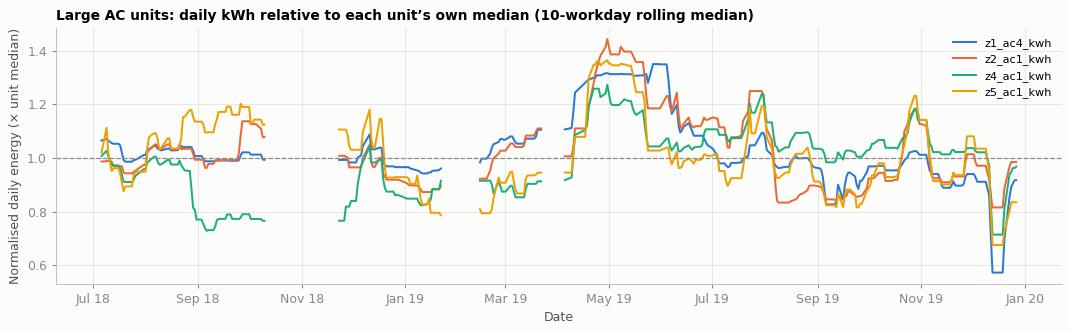

In [28]:
AC_KWH = [c.replace('_kw', '_kwh') for c in AC_COLS]
LARGE_KWH = [c.replace('_kw', '_kwh') for c in LARGE_AC]
on_threshold_kw = (p999[AC_COLS] * CFG['on_frac_p999']).rename(index=lambda c: c.replace('_kw', '_kwh'))
valid_day = q15[AC_KWH].notna().groupby(q15.date).mean() >= CFG['min_coverage']
ac_daily = q15.groupby('date')[AC_KWH].sum(min_count=1).where(valid_day)
ac_runh = (q15[AC_KWH] * 4 > on_threshold_kw).groupby(q15.date).sum().div(4).where(valid_day)
day_type_of = q15.groupby('date').day_type.first()
day_class = np.where(day_type_of == 'workday', 'workday', 'non_workday')

# 1) against own history
self_rows = []
for col in AC_KWH:
    for cls in ['workday', 'non_workday']:
        s = ac_daily.loc[day_class == cls, col].dropna()
        n = CFG['residual_window_days'][cls]
        hist = s.shift(1).rolling(n, min_periods=n // 2)
        med = hist.median()
        scale = hist.apply(mad_scale, raw=True).clip(lower=0.5)   # DECISION: MAD floor of 0.5 kWh avoids z = inf on always-off units
        z = (s - med) / scale
        flag = (z > CFG['robust_z']) & (s - med >= CFG['ac_self_min_excess_kwh'])
        for d in s.index[flag]:
            self_rows.append({'timestamp_start': d, 'timestamp_end': d + pd.Timedelta('1D'), 'zone': zone_of[col.replace('_kwh', '_kw')],
                              'variable': col, 'magnitude': ac_runh.at[d, col], 'excess_kWh': s[d] - med[d]})
op_ac_self = to_records(pd.DataFrame(self_rows), anomaly_type='operational/ac_unit_vs_own_history',
                        rule_used='daily kWh robust z > 3.5 (MAD floor 0.5 kWh) and >= 1 kWh above trailing median of 20 workdays / 8 non-workdays; magnitude = run-hours that day')

# 2) against peers on the same day (large units, working days, all four present)
peer = ac_daily.loc[day_class == 'workday', LARGE_KWH].dropna()
norm = peer / peer.median()
peer_rows, peer_ratios = [], {}
for col in LARGE_KWH:
    others = norm.drop(columns=col).median(axis=1)
    ratio = norm[col] / others.where(others > 0.2)
    peer_ratios[col] = ratio
    typical = peer[col].median()
    for d in ratio.index[(ratio > CFG['peer_ratio_high']) | (ratio < CFG['peer_ratio_low'])]:
        peer_rows.append({'timestamp_start': d, 'timestamp_end': d + pd.Timedelta('1D'), 'zone': zone_of[col.replace('_kwh', '_kw')],
                          'variable': col, 'magnitude': round(ratio[d], 2),
                          'excess_kWh': peer.at[d, col] - others[d] * typical})
op_ac_peer = to_records(pd.DataFrame(peer_rows), anomaly_type='operational/ac_unit_vs_peers',
                        rule_used='large units, workdays: (unit kWh / unit median) / median of peers > 1.5 or < 0.5; magnitude = ratio')
print(f'AC own-history flags: {len(op_ac_self)} unit-days; peer flags: {len(op_ac_peer)} unit-days '
      f'({(op_ac_peer.magnitude > 1).sum()} high, {(op_ac_peer.magnitude < 1).sum()} low)')
print('Peer ratio (unit vs peers, working days) 1st / 50th / 99th percentile:',
      {c: [round(float(v), 2) for v in r.quantile([0.01, 0.5, 0.99])] for c, r in peer_ratios.items()})

summary = pd.DataFrame({'median_workday_kwh': ac_daily[day_class == 'workday'].median(),
                        'median_workday_run_h': ac_runh[day_class == 'workday'].median(),
                        'non_workday_run_h_total': ac_runh[day_class != 'workday'].sum(),
                        'on_threshold_kw': on_threshold_kw})
display(summary.round(2))

fig, ax = plt.subplots(figsize=(12, 3.8))
rolling_norm = norm.rolling(10, min_periods=5).median()
rolling_norm[rolling_norm.index.to_series().diff() > pd.Timedelta('7D')] = np.nan   # break the line across data gaps > 7 days
for i, col in enumerate(LARGE_KWH):
    ax.plot(rolling_norm.index, rolling_norm[col], color=PALETTE[i], label=col)
ax.axhline(1, color=MUTED, linewidth=1, linestyle='--')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
label_axes(ax, 'Large AC units: daily kWh relative to each unit’s own median (10-workday rolling median)',
           'Date', 'Normalised daily energy (× unit median)')
plt.tight_layout()
plt.show()

### 7c. AC running while the zone is already cold, or not reaching comfort despite high load
Checked at 15-minute resolution for zones that have both AC and a sensor (z1, z2, z4, z5), and only where temperature data exists.
- **Over-cooling:** zone AC on and zone temperature below **23 °C**. This is aggregated per zone-day and needs at least 1 h. The estimated excess is `AC kWh × 3%/°C × degrees below 23 °C`. **The 3%/°C factor is an assumption to replace with a cited value.**
- **Under-cooling:** zone AC above 80% of its typical on-load while the zone is above **26 °C** for at least 1 h, excluding the first hour after switch-on (normal pull-down).

In [29]:
AC_ZONES = [z for z in ZONES if f'{z}_temp_c' in q15 and f'{z}_ac_total_kwh' in q15]
comfort_rows, over_rows, under_rows = [], [], []
for zone in AC_ZONES:
    ac_kw = q15[f'{zone}_ac_total_kwh'] * 4
    main_unit = max((c for c in AC_COLS if zone_of[c] == zone), key=lambda c: p999[c])
    on = ac_kw > p999[main_unit] * CFG['on_frac_p999']
    temp = q15[f'{zone}_temp_c']
    has_t = temp.notna()
    comfort_rows.append({'zone': zone, 'ac_on_hours_with_temp': (on & has_t).sum() / 4,
                         'median_temp_when_on': temp[on].median(),
                         f'share_below_{CFG["comfort_low_c"]:.0f}C': (temp[on & has_t] < CFG['comfort_low_c']).mean(),
                         f'share_above_{CFG["comfort_high_c"]:.0f}C': (temp[on & has_t] > CFG['comfort_high_c']).mean()})
    # Over-cooling, aggregated per zone-day
    deficit = (CFG['comfort_low_c'] - temp).clip(lower=0)
    oc = pd.DataFrame({'flag': on & (temp < CFG['comfort_low_c']), 'deficit': deficit, 'ac_kwh': ac_kw / 4, 'date': q15.date})
    oc = oc[oc.flag]
    oc['excess'] = oc.ac_kwh * CFG['overcool_sensitivity_per_c'] * oc.deficit
    per_day = oc.groupby('date').agg(timestamp_start=('flag', lambda s: s.index.min()), timestamp_end=('flag', lambda s: s.index.max()),
                                     n=('flag', 'size'), degree_hours=('deficit', lambda s: s.sum() / 4), excess_kWh=('excess', 'sum'))
    per_day = per_day[per_day.n * 15 >= CFG['overcool_min_minutes']]
    over_rows.append(per_day.assign(zone=zone, variable=f'{zone}_ac_total_kwh & {zone}_temp_c',
                                    timestamp_end=per_day.timestamp_end + pd.Timedelta('15min'),
                                    magnitude=per_day.degree_hours.round(1)))
    # Under-cooling
    run_id = (on != on.shift()).cumsum()
    minutes_on = on.groupby(run_id).cumcount() * 15
    high_load = ac_kw > 0.8 * ac_kw[on].quantile(0.95)
    uc = pd.DataFrame({'flag': on & high_load & (temp > CFG['comfort_high_c']) & (minutes_on >= CFG['pulldown_exclusion_min']),
                       'over': temp - CFG['comfort_high_c']})
    ev = flagged_events(uc, 'flag', '15min', max_over=('over', 'max'))
    if not ev.empty:
        ev = ev[ev.n_intervals * 15 >= CFG['undercool_min_minutes']]
        under_rows.append(ev.assign(zone=zone, variable=f'{zone}_ac_total_kwh & {zone}_temp_c', magnitude=ev.max_over.round(2)))

comfort = pd.DataFrame(comfort_rows).set_index('zone')
op_overcool = to_records(pd.concat(over_rows), anomaly_type='operational/ac_overcooling',
                         rule_used=f"AC on & zone temp < {CFG['comfort_low_c']} C for >= 1 h/day; excess = AC kWh x {CFG['overcool_sensitivity_per_c']:.0%}/C x deficit (ASSUMED factor); magnitude = degree-hours")
op_undercool = to_records(pd.concat(under_rows) if under_rows else pd.DataFrame(), anomaly_type='operational/ac_high_load_not_cooling',
                          rule_used=f"AC > 80% of on-P95 & temp > {CFG['comfort_high_c']} C for >= 1 h, excl. first hour after start; magnitude = max degC above")
display(comfort.round(2))
print(f'Over-cooling zone-days: {len(op_overcool)} (est. {op_overcool.excess_kWh.sum():,.0f} kWh at the assumed factor); '
      f'high-load-not-cooling events: {len(op_undercool)}')

,ac_on_hours_with_temp,median_temp_when_on,share_below_23C,share_above_26C
zone,,,,
z1,"1,596.750",22.260,0.670,0.040
z2,"1,720.000",21.730,0.680,0.040
z4,"1,606.250",18.510,0.940,0.010
z5,"1,190.250",19.630,0.930,0.010


Over-cooling zone-days: 821 (est. 6,536 kWh at the assumed factor); high-load-not-cooling events: 0


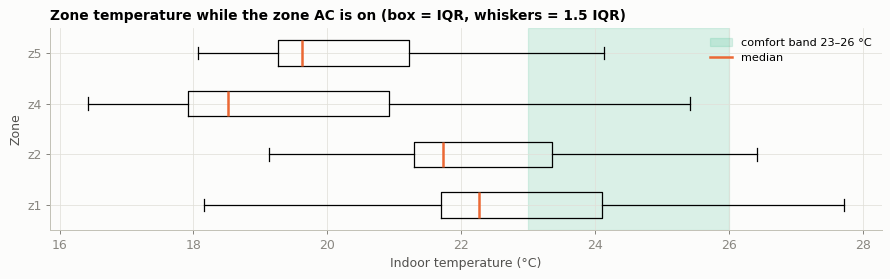

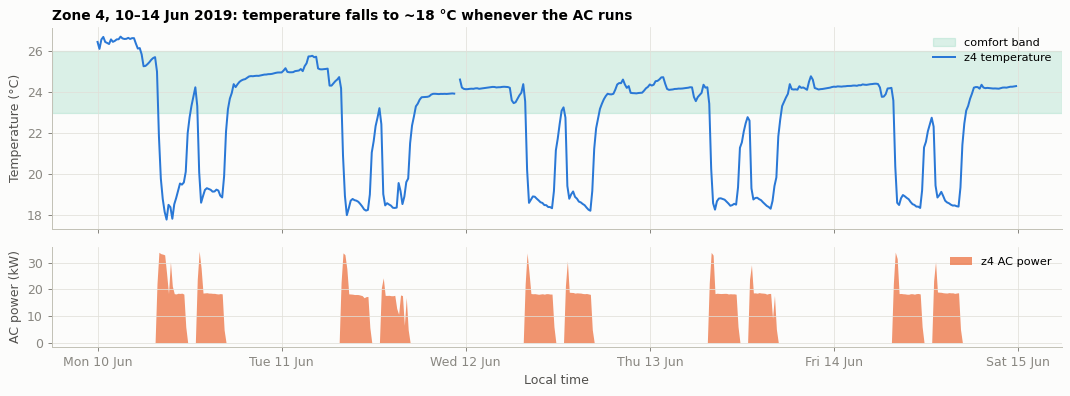

In [30]:
temps_on = []
for zone in AC_ZONES:
    main_unit = max((c for c in AC_COLS if zone_of[c] == zone), key=lambda c: p999[c])
    on = q15[f'{zone}_ac_total_kwh'] * 4 > p999[main_unit] * CFG['on_frac_p999']
    temps_on.append(q15.loc[on, f'{zone}_temp_c'].dropna())
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axvspan(CFG['comfort_low_c'], CFG['comfort_high_c'], color=PALETTE[2], alpha=0.15, label='comfort band 23–26 °C')
ax.boxplot(temps_on, vert=False, tick_labels=AC_ZONES, showfliers=False, widths=0.5,
           medianprops={'color': PALETTE[1], 'linewidth': 2})
ax.plot([], [], color=PALETTE[1], linewidth=2, label='median')
label_axes(ax, 'Zone temperature while the zone AC is on (box = IQR, whiskers = 1.5 IQR)', 'Indoor temperature (°C)', 'Zone')
plt.tight_layout()
plt.show()

# One typical working week in zone 4: two panels on a shared time axis (no dual y-axis)
week = q15.loc['2019-06-10':'2019-06-14']
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax1.axhspan(CFG['comfort_low_c'], CFG['comfort_high_c'], color=PALETTE[2], alpha=0.15, label='comfort band')
ax1.plot(week.index, week['z4_temp_c'], color=PALETTE[0], label='z4 temperature')
label_axes(ax1, 'Zone 4, 10–14 Jun 2019: temperature falls to ~18 °C whenever the AC runs', '', 'Temperature (°C)')
ax2.fill_between(week.index, week['z4_ac_total_kwh'] * 4, color=PALETTE[1], alpha=0.7, linewidth=0, label='z4 AC power')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b', tz=TZ))
label_axes(ax2, '', 'Local time', 'AC power (kW)')
plt.tight_layout()
plt.show()

### 7d. Lighting on while daylight is available
**Caveat found in the data:** each zone's lux sensor tracks its own lamps closely (correlation 0.91–0.96 with lighting kW), so "lights on while lux is high" would be circular. Instead, the daylight effect is separated from the lamp effect with the external **solar radiation** data. For daytime hours only (sun above the horizon for the whole hour, from `astral`):

`lux = a × lighting kW + b × outdoor solar radiation (W/m²) + c`

`a × kW` estimates the lamps' contribution and `b × solar` the daylight reaching the sensor. An hour is flagged when lights are on and the estimated daylight is at least 50% of the lamps' contribution. The potential saving is `lighting kWh × daylight share` (capped at 50%).

,daytime_hours,a_lux_per_kW,b_lux_per_Wm2,se_b,R2,lamp_lux_typical,daylight_lux_at_600Wm2,lit_hours_flagged_%
zone,,,,,,,,
z1,3833,7.190,0.003,0.000,0.839,33.518,1.738,0.000
z2,3942,11.944,-0.003,0.001,0.903,67.990,-1.803,0.000
z4,3983,12.022,0.005,0.000,0.848,33.981,2.957,0.000
z5,3304,14.733,0.004,0.000,0.949,33.335,2.139,0.000


Lighting-with-daylight events: 0, potential 0.0 kWh. Daylight at 600 W/m2 adds -1.8-3.0 lux vs 33-68 lux from the lamps.


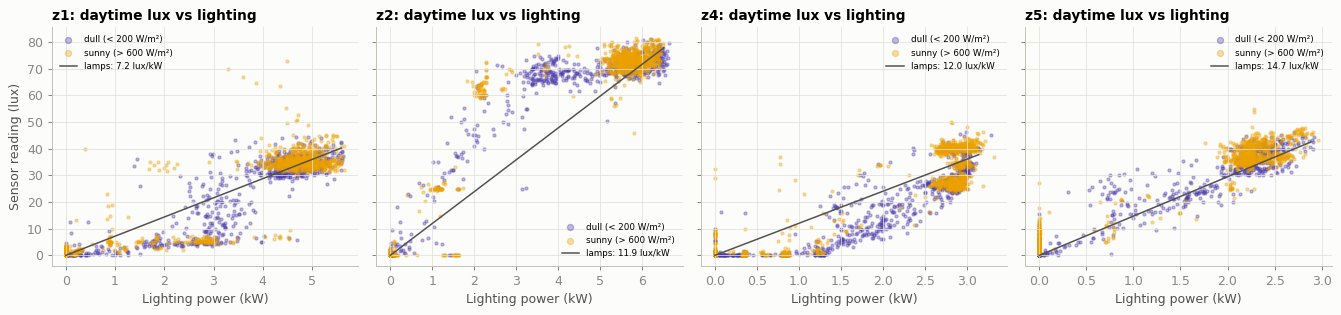

In [31]:
hour_start = pd.Series(hourly.index, index=hourly.index)
full_daylight = (hour_start >= hourly.date.map(sun_times.sunrise)) & (hour_start + pd.Timedelta('1h') <= hourly.date.map(sun_times.sunset))


def fit_lux_model(zone):
    # OLS of daytime lux on lighting kW and outdoor solar radiation; returns coefficients, SE of b, R2 and the data used.
    d = pd.DataFrame({'kw': hourly[f'{zone}_light_kwh'], 'lux': hourly[f'{zone}_lux'], 'solar': hourly.solar_wm2})
    d = d[full_daylight].dropna()
    X = np.column_stack([d.kw, d.solar, np.ones(len(d))])
    beta, *_ = np.linalg.lstsq(X, d.lux.to_numpy(), rcond=None)
    resid = d.lux.to_numpy() - X @ beta
    se = np.sqrt(np.diag(resid.var(ddof=3) * np.linalg.inv(X.T @ X)))
    r2 = 1 - (resid ** 2).sum() / ((d.lux - d.lux.mean()) ** 2).sum()
    return beta, se[1], r2, d


lux_rows, light_events, lux_fits = [], [], {}
for zone in [z for z in ZONES if f'{z}_lux' in hourly]:
    (a, b, c), se_b, r2, d = fit_lux_model(zone)
    lux_fits[zone] = (a, b, d)
    lamp_lux = a * d.kw
    daylight_lux = (b * d.solar).clip(lower=0)
    lit = d.kw > p999[f'{zone}_light_kw'] * CFG['on_frac_p999']
    d['flag'] = lit & (daylight_lux >= CFG['daylight_share_flag'] * lamp_lux)
    d['potential'] = d.kw * (daylight_lux / (daylight_lux + lamp_lux)).clip(upper=0.5)
    d['daylight_lux'] = daylight_lux
    ev = flagged_events(d, 'flag', '1h', excess_kWh=('potential', 'sum'), mean_daylight_lux=('daylight_lux', 'mean'))
    if not ev.empty:
        light_events.append(ev.assign(zone=zone, variable=f'{zone}_light_kwh & {zone}_lux', magnitude=ev.mean_daylight_lux.round(1)))
    lux_rows.append({'zone': zone, 'daytime_hours': len(d), 'a_lux_per_kW': a, 'b_lux_per_Wm2': b, 'se_b': se_b, 'R2': r2,
                     'lamp_lux_typical': a * d.kw[lit].median(), 'daylight_lux_at_600Wm2': b * 600,
                     'lit_hours_flagged_%': d.flag[lit].mean() * 100})

op_daylight = to_records(pd.concat(light_events) if light_events else pd.DataFrame(), anomaly_type='operational/lighting_with_daylight',
                         rule_used='daytime hour, lights on, b*solar >= 50% of a*kW from OLS lux ~ kW + solar; excess = light kWh x daylight share (cap 50%); magnitude = mean daylight lux')
lux_table = pd.DataFrame(lux_rows).set_index('zone')
display(lux_table.round(3))
print(f'Lighting-with-daylight events: {len(op_daylight)}, potential {op_daylight.excess_kWh.sum():,.1f} kWh. '
      f'Daylight at 600 W/m2 adds {lux_table.daylight_lux_at_600Wm2.min():.1f}-{lux_table.daylight_lux_at_600Wm2.max():.1f} lux vs '
      f'{lux_table.lamp_lux_typical.min():.0f}-{lux_table.lamp_lux_typical.max():.0f} lux from the lamps.')

fig, axes = plt.subplots(1, len(lux_fits), figsize=(15, 3.6), sharey=True)
for ax, (zone, (a, b, d)) in zip(axes, lux_fits.items()):
    for mask, colour, label in [(d.solar < 200, PALETTE[6], 'dull (< 200 W/m²)'), (d.solar > 600, PALETTE[3], 'sunny (> 600 W/m²)')]:
        ax.scatter(d.kw[mask], d.lux[mask], s=6, alpha=0.35, color=colour, label=label)
    xs = np.linspace(0, d.kw.quantile(0.995), 20)
    ax.plot(xs, a * xs, color=INK, linewidth=1.2, label=f'lamps: {a:.1f} lux/kW')
    label_axes(ax, f'{zone}: daytime lux vs lighting', 'Lighting power (kW)', 'Sensor reading (lux)' if ax is axes[0] else '')
    ax.legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

### 7e. Baseline residuals: actual vs expected energy
**Model 1: time-of-week profile (robust, adaptive).** For each hour, the expected floor kWh is the median of the same hour over the previous 20 working days (or 8 non-working days; holidays and closure days count as non-working). The scale is the rolling MAD of the same window. An hour is flagged when `actual − expected > max(3.5 × 1.4826 × MAD, 5 kWh)`, and consecutive flagged hours merge into events.

**Model 2: weather-normalised daily AC.** Daily working-day AC kWh is regressed on the mean outdoor temperature during 08:00–17:00 (Open-Meteo). Days whose robust residual z exceeds 3.5 are flagged. This model is also used to check whether Model 1 events can be explained by **hot weather** rather than operation.

In [32]:
def rolling_slot_baseline(frame, value_col):
    """Expected value and robust scale per hour from previous same-hour values in the same day class."""
    cls = np.where(frame.day_type == 'workday', 'workday', 'non_workday')
    expected = pd.Series(np.nan, index=frame.index)
    scale = pd.Series(np.nan, index=frame.index)
    for (c, hour), g in frame.groupby([cls, frame.hour])[value_col]:
        n = CFG['residual_window_days'][c]
        hist = g.shift(1).rolling(n, min_periods=n // 2)
        expected[g.index] = hist.median()
        scale[g.index] = hist.apply(mad_scale, raw=True)
    return expected, scale


hourly['expected_kwh'], hourly['scale_kwh'] = rolling_slot_baseline(hourly, 'floor_total_kwh')
hourly['residual_kwh'] = hourly.floor_total_kwh - hourly.expected_kwh
hourly['resid_threshold'] = np.maximum(CFG['robust_z'] * hourly.scale_kwh, CFG['residual_min_excess_kwh'])
hourly['resid_flag'] = hourly.residual_kwh > hourly.resid_threshold
for end_use in ['ac', 'light', 'plug']:
    exp_eu, _ = rolling_slot_baseline(hourly, f'floor_{end_use}_kwh')
    hourly[f'resid_{end_use}'] = hourly[f'floor_{end_use}_kwh'] - exp_eu

res_ev = flagged_events(hourly, 'resid_flag', '1h', excess_kWh=('residual_kwh', 'sum'), peak=('residual_kwh', 'max'),
                        ac=('resid_ac', 'sum'), light=('resid_light', 'sum'), plug=('resid_plug', 'sum'))
res_ev['main_driver'] = res_ev[['ac', 'light', 'plug']].idxmax(axis=1)
op_residual = to_records(res_ev.assign(zone='floor', variable='floor_total_kwh (driver: ' + res_ev.main_driver + ')',
                                       magnitude=res_ev.peak.round(1)),
                         anomaly_type='operational/baseline_residual',
                         rule_used='hourly floor kWh - rolling same-hour median (20 workdays / 8 non-workdays) > max(3.5*MAD, 5 kWh); magnitude = peak hourly excess kWh')
valid_hours = hourly.residual_kwh.notna()
print(f'Residual model: {hourly.resid_flag.sum()} flagged hours out of {valid_hours.sum():,} evaluable '
      f'({hourly.resid_flag.sum() / valid_hours.sum():.2%}), merged into {len(op_residual)} events, '
      f'{op_residual.excess_kWh.sum():,.0f} kWh')

Residual model: 237 flagged hours out of 10,323 evaluable (2.30%), merged into 100 events, 3,754 kWh


Weather model: AC kWh = -398 + 30.1 x T_out (R2 = 0.43, n = 306 workdays); 0 days flagged
Residual events on the hottest 10% of days: 16 of 100; of those, 1 look normal once weather is accounted for (weather z < 2).


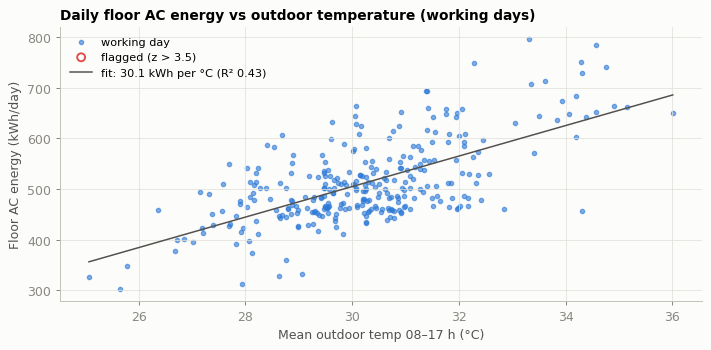

In [33]:
# Model 2: weather-normalised daily AC (working days, complete data)
day_weather = hourly[hourly.hour.between(8, 16)].groupby('date')[['out_temp_c', 'solar_wm2']].mean()
wd = daily[daily.day_type == 'workday'].join(day_weather, rsuffix='_day').dropna(subset=['ac_kwh', 'out_temp_c_day'])
slope, intercept = np.polyfit(wd.out_temp_c_day, wd.ac_kwh, 1)
wd['expected_ac'] = intercept + slope * wd.out_temp_c_day
wd['resid'] = wd.ac_kwh - wd.expected_ac
wd['z'] = (wd.resid - wd.resid.median()) / mad_scale(wd.resid)
r2_weather = 1 - (wd.resid ** 2).sum() / ((wd.ac_kwh - wd.ac_kwh.mean()) ** 2).sum()
flag_w = wd[wd.z > CFG['robust_z']]
op_weather = to_records(pd.DataFrame({'timestamp_start': flag_w.index, 'timestamp_end': flag_w.index + pd.Timedelta('1D'),
                                      'zone': 'floor', 'variable': 'floor_ac_kwh (daily)', 'magnitude': flag_w.z.round(1).to_numpy(),
                                      'excess_kWh': flag_w.resid.to_numpy()}),
                        anomaly_type='operational/ac_daily_excess_weather_adjusted',
                        rule_used='workday AC kWh vs linear fit on 08-17h outdoor temp; robust z > 3.5; magnitude = robust z')
print(f'Weather model: AC kWh = {intercept:.0f} + {slope:.1f} x T_out (R2 = {r2_weather:.2f}, n = {len(wd)} workdays); '
      f'{len(op_weather)} days flagged')

# Can hot weather explain the Model 1 events?
op_residual['event_date'] = op_residual.timestamp_start.dt.normalize()
op_residual['weather_z'] = op_residual.event_date.map(wd.z)
op_residual['out_temp_c'] = op_residual.event_date.map(day_weather.out_temp_c)
hot = op_residual.out_temp_c > day_weather.out_temp_c.quantile(0.9)
print(f'Residual events on the hottest 10% of days: {hot.sum()} of {len(op_residual)}; '
      f'of those, {((op_residual.weather_z < 2) & hot).sum()} look normal once weather is accounted for (weather z < 2).')

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(wd.out_temp_c_day, wd.ac_kwh, s=12, alpha=0.6, color=PALETTE[0], label='working day')
ax.scatter(flag_w.out_temp_c_day, flag_w.ac_kwh, s=40, facecolor='none', edgecolor=PALETTE[7], linewidth=1.5, label='flagged (z > 3.5)')
xs = np.linspace(wd.out_temp_c_day.min(), wd.out_temp_c_day.max(), 10)
ax.plot(xs, intercept + slope * xs, color=INK, linewidth=1.2, label=f'fit: {slope:.1f} kWh per °C (R² {r2_weather:.2f})')
label_axes(ax, 'Daily floor AC energy vs outdoor temperature (working days)', 'Mean outdoor temp 08–17 h (°C)', 'Floor AC energy (kWh/day)')
plt.tight_layout()
plt.show()

In [34]:
# Why the holiday calendar matters: re-run the earlier notebook's rule (median by year/weekend/hour, 6 x MAD, |residual|).
old = hourly[['floor_total_kwh', 'year', 'is_weekend', 'hour', 'is_holiday', 'day_type']].dropna(subset=['floor_total_kwh']).copy()
old['baseline'] = old.groupby(['year', 'is_weekend', 'hour']).floor_total_kwh.transform('median')
old['resid'] = old.floor_total_kwh - old.baseline
scale = old.groupby('year').resid.transform(lambda r: (r - r.median()).abs().median())
old['flag'] = old.resid.abs() > 6 * scale.replace(0, np.nan)
top20 = old[old.flag].reindex(old[old.flag].resid.abs().sort_values(ascending=False).index).head(20)
print(f"Earlier rule: {old.flag.mean():.1%} of hours flagged; top-20 events on holidays/closure days: "
      f"{top20.day_type.isin(['holiday', 'closure']).mean():.0%}. New model flags {hourly.resid_flag.sum() / valid_hours.sum():.2%} of hours.")

Earlier rule: 25.9% of hours flagged; top-20 events on holidays/closure days: 100%. New model flags 2.30% of hours.


### 7f. Combined anomaly table and export

In [35]:
parts = [op_after_hours, op_ac_self, op_ac_peer, op_overcool, op_undercool, op_daylight, op_residual[ANOMALY_COLUMNS], op_weather]
operational = pd.concat([p for p in parts if not p.empty], ignore_index=True)
anomalies = pd.concat([dq_anomalies, operational], ignore_index=True)
anomalies['excess_kWh'] = anomalies.excess_kWh.astype(float).round(2)
anomalies = anomalies.sort_values(['anomaly_type', 'timestamp_start']).reset_index(drop=True)
out_path = OUTPUT_DIR / f'floor{FLOOR}_anomalies.csv'
anomalies.to_csv(out_path, index=False)

by_type = anomalies.groupby('anomaly_type').agg(events=('anomaly_type', 'size'),
                                                excess_kWh=('excess_kWh', lambda s: s.clip(lower=0).sum(min_count=1)),
                                                first=('timestamp_start', 'min'), last=('timestamp_start', 'max'))
print(f'Exported {len(anomalies):,} anomalies -> {out_path.relative_to(REPO_ROOT)}')
display(by_type.round(0))

Exported 2,045 anomalies -> workspace\outputs\floor3_anomalies.csv


,events,excess_kWh,first,last
anomaly_type,,,,
data_quality/gap_ge_60min,109,NaN,2018-07-04 16:58:00+07:00,2019-12-26 04:27:00+07:00
data_quality/power_spike,344,NaN,2018-09-19 13:05:00+07:00,2019-12-18 12:39:00+07:00
operational/ac_overcooling,821,"6,536.000",2018-07-02 08:15:00+07:00,2019-12-27 08:15:00+07:00
operational/ac_unit_vs_own_history,110,"3,399.000",2018-07-23 00:00:00+07:00,2019-12-25 00:00:00+07:00
operational/after_hours_load,561,"5,427.000",2018-07-07 07:45:00+07:00,2019-12-27 20:30:00+07:00
operational/baseline_residual,100,"3,754.000",2018-07-21 11:00:00+07:00,2019-12-27 20:00:00+07:00


## 8. Insights: top candidate anomalies

The table ranks operational anomalies by excess kWh, with plain-English interpretations generated from each record. Because the categories overlap (see 7), the ranking shows *where to look first*; it is not an additive savings total. The over-cooling excess depends on an assumed 3%/°C factor.

In [36]:
TEMPLATES = {
    'operational/after_hours_load': 'Candidate anomaly: {variable} drew {excess:.1f} kWh above its night baseload outside its usual hours ({when}). Flagged for investigation: equipment left on, or a schedule override?',
    'operational/ac_unit_vs_own_history': 'Candidate anomaly: {variable} ran {mag} h and used {excess:.1f} kWh more than its recent typical for that day type ({when}). Check for manual override or a control change.',
    'operational/ac_unit_vs_peers': 'Candidate anomaly: {variable} ran at {mag}x its peers’ normalised load ({when}); {excess:.1f} kWh above peer expectation. Check the zone thermostat / unit controls.',
    'operational/ac_overcooling': 'Candidate anomaly: {zone} was held below 23 °C while its AC ran ({mag} degree-hours, {when}); ~{excess:.1f} kWh at the assumed 3%/°C. Check the setpoint.',
    'operational/ac_high_load_not_cooling': 'Candidate anomaly: {zone} stayed above 26 °C despite high AC load ({when}). Flag for maintenance inspection.',
    'operational/lighting_with_daylight': 'Candidate anomaly: {zone} lights on while daylight added ~{mag} lux ({when}); ~{excess:.1f} kWh dimmable.',
    'operational/baseline_residual': 'Candidate anomaly: floor energy {excess:.1f} kWh above the rolling same-hour baseline ({when}); {variable}.',
    'operational/ac_daily_excess_weather_adjusted': 'Candidate anomaly: floor AC {excess:.1f} kWh above what the outdoor temperature predicts ({when}, z = {mag}).',
}


def describe_when(ts):
    name = HOLIDAY_NAMES.get(ts.normalize())
    kind = f'holiday: {name.split(";")[0]}' if isinstance(name, str) else ('weekend' if ts.dayofweek >= 5 else 'weekday')
    return f'{ts:%a %d %b %Y %H:%M}, {kind}'


def interpret(row):
    return TEMPLATES[row.anomaly_type].format(variable=row.variable, zone=row.zone, excess=row.excess_kWh,
                                              mag=row.magnitude, when=describe_when(row.timestamp_start))


top = operational.dropna(subset=['excess_kWh']).sort_values('excess_kWh', ascending=False).head(10).copy()
top['duration_h'] = ((top.timestamp_end - top.timestamp_start).dt.total_seconds() / 3600).round(1)
top['interpretation'] = top.apply(interpret, axis=1)
display(top[['timestamp_start', 'duration_h', 'zone', 'anomaly_type', 'excess_kWh']].round(1))
for i, text in enumerate(top.interpretation.head(5), 1):
    print(f'{i}. {text}')

,timestamp_start,duration_h,zone,anomaly_type,excess_kWh
1507,2018-09-08 10:00:00+07:00,9.000,floor,operational/baseline_residual,295.600
1564,2019-09-14 07:00:00+07:00,10.000,floor,operational/baseline_residual,283.800
1565,2019-09-15 09:00:00+07:00,7.000,floor,operational/baseline_residual,228.100
616,2019-04-27 00:00:00+07:00,24.000,z1,operational/ac_unit_vs_own_history,209.500
1540,2019-05-09 07:00:00+07:00,3.000,floor,operational/baseline_residual,187.600
1536,2019-04-27 07:00:00+07:00,5.000,floor,operational/baseline_residual,173.500
1537,2019-04-27 13:00:00+07:00,4.000,floor,operational/baseline_residual,158.300
614,2018-09-08 00:00:00+07:00,24.000,z1,operational/ac_unit_vs_own_history,153.300
54,2018-09-08 10:15:00+07:00,8.200,z1,operational/after_hours_load,153.300
638,2019-04-27 00:00:00+07:00,24.000,z2,operational/ac_unit_vs_own_history,124.600


1. Candidate anomaly: floor energy 295.6 kWh above the rolling same-hour baseline (Sat 08 Sep 2018 10:00, weekend); floor_total_kwh (driver: ac).
2. Candidate anomaly: floor energy 283.8 kWh above the rolling same-hour baseline (Sat 14 Sep 2019 07:00, weekend); floor_total_kwh (driver: ac).
3. Candidate anomaly: floor energy 228.1 kWh above the rolling same-hour baseline (Sun 15 Sep 2019 09:00, weekend); floor_total_kwh (driver: ac).
4. Candidate anomaly: z1_ac4_kwh ran 7.25 h and used 209.5 kWh more than its recent typical for that day type (Sat 27 Apr 2019 00:00, weekend). Check for manual override or a control change.
5. Candidate anomaly: floor energy 187.6 kWh above the rolling same-hour baseline (Thu 09 May 2019 07:00, holiday: Royal Ploughing Ceremony); floor_total_kwh (driver: ac).


**Incident view (no double counting).** One event can trigger several rules, for example a weekend AC run is flagged by 7a, 7b and 7e. Below, the records are grouped by calendar day. Each day is scored by the larger of its summed floor-level residual excess (which already covers every circuit) or its largest single record, never the sum across rules. Over-cooling is left out here because it is **systemic** (it happens on almost every AC day) and is tracked as a KPI instead.

In [37]:
src = operational[operational.anomaly_type != 'operational/ac_overcooling'].dropna(subset=['excess_kWh']).copy()
src['day'] = src.timestamp_start.dt.normalize()
lead = src.loc[src.groupby('day').excess_kWh.idxmax()].set_index('day')
incidents = src.groupby('day').agg(records=('anomaly_type', 'size'),
                                   rules=('anomaly_type', lambda s: ', '.join(sorted({t.split('/')[1] for t in s}))))
incidents = incidents.join(lead[['excess_kWh', 'zone', 'variable', 'anomaly_type', 'timestamp_start', 'timestamp_end', 'magnitude']])
# Floor-level residual events already include every circuit, so a day's score is the larger of (sum of its residual events,
# largest single record). The morning and afternoon AC blocks often form two residual events split by the lunch shutdown.
floor_resid_day = src[src.anomaly_type == 'operational/baseline_residual'].groupby('day').excess_kWh.sum()
incidents['day_excess_kWh'] = np.fmax(incidents.excess_kWh, floor_resid_day.reindex(incidents.index))
incidents = incidents.sort_values('day_excess_kWh', ascending=False)
incidents['interpretation'] = [interpret(r) + f' [rules fired that day: {r.rules}]' for r in incidents.itertuples()]
print(f'{len(incidents)} candidate incident-days (excluding systemic over-cooling). Top 5:')
display(incidents[['day_excess_kWh', 'records', 'rules']].head(5).round(1))
for i, (day, r) in enumerate(incidents.head(5).iterrows(), 1):
    print(f'{i}. {describe_when(day)[:15]}: ~{r.day_excess_kWh:.0f} kWh excess for the day. Lead record -> {r.interpretation}')

224 candidate incident-days (excluding systemic over-cooling). Top 5:


,day_excess_kWh,records,rules
day,,,
2019-04-27 00:00:00+07:00,331.900,8,"ac_unit_vs_own_history, after_hours_load, base..."
2018-09-08 00:00:00+07:00,295.600,9,"ac_unit_vs_own_history, after_hours_load, base..."
2019-09-14 00:00:00+07:00,283.800,15,"ac_unit_vs_own_history, after_hours_load, base..."
2019-09-15 00:00:00+07:00,228.100,10,"ac_unit_vs_own_history, after_hours_load, base..."
2019-05-09 00:00:00+07:00,192.700,14,"ac_unit_vs_own_history, after_hours_load, base..."


1. Sat 27 Apr 2019: ~332 kWh excess for the day. Lead record -> Candidate anomaly: z1_ac4_kwh ran 7.25 h and used 209.5 kWh more than its recent typical for that day type (Sat 27 Apr 2019 00:00, weekend). Check for manual override or a control change. [rules fired that day: ac_unit_vs_own_history, after_hours_load, baseline_residual]
2. Sat 08 Sep 2018: ~296 kWh excess for the day. Lead record -> Candidate anomaly: floor energy 295.6 kWh above the rolling same-hour baseline (Sat 08 Sep 2018 10:00, weekend); floor_total_kwh (driver: ac). [rules fired that day: ac_unit_vs_own_history, after_hours_load, baseline_residual]
3. Sat 14 Sep 2019: ~284 kWh excess for the day. Lead record -> Candidate anomaly: floor energy 283.8 kWh above the rolling same-hour baseline (Sat 14 Sep 2019 07:00, weekend); floor_total_kwh (driver: ac). [rules fired that day: ac_unit_vs_own_history, after_hours_load, baseline_residual]
4. Sun 15 Sep 2019: ~228 kWh excess for the day. Lead record -> Candidate anomaly:

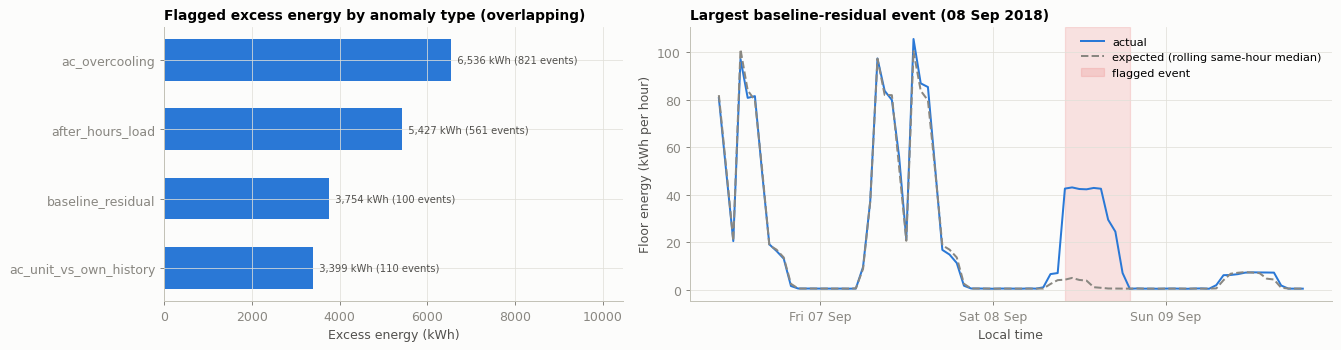

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 1.4]})
op_types = by_type.loc[by_type.index.str.startswith('operational')].sort_values('excess_kWh')
ax = axes[0]
ax.barh(op_types.index.str.replace('operational/', ''), op_types.excess_kWh, color=PALETTE[0], height=0.6)
for y, (v, n) in enumerate(zip(op_types.excess_kWh, op_types.events)):
    ax.text(v, y, f'  {v:,.0f} kWh ({n} events)', va='center', fontsize=8, color=INK)
ax.set_xlim(0, op_types.excess_kWh.max() * 1.6)
label_axes(ax, 'Flagged excess energy by anomaly type (overlapping)', 'Excess energy (kWh)', '', legend=False)

# Largest residual event in context: actual vs expected
ev = op_residual.sort_values('excess_kWh', ascending=False).iloc[0]
ctx = hourly.loc[ev.timestamp_start - pd.Timedelta('2D'): ev.timestamp_end + pd.Timedelta('1D')]
ax = axes[1]
ax.plot(ctx.index, ctx.floor_total_kwh, color=PALETTE[0], label='actual')
ax.plot(ctx.index, ctx.expected_kwh, color=MUTED, linestyle='--', label='expected (rolling same-hour median)')
ax.axvspan(ev.timestamp_start, ev.timestamp_end, color=PALETTE[7], alpha=0.15, label='flagged event')
ax.xaxis.set_major_locator(mdates.DayLocator(tz=TZ))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b', tz=TZ))
label_axes(ax, f'Largest baseline-residual event ({ev.timestamp_start:%d %b %Y})', 'Local time', 'Floor energy (kWh per hour)')
plt.tight_layout()
plt.show()

### Interpretation
*Written from the run on 24 Sep 2026 with the thresholds in `CFG`. Re-check these numbers if you change a threshold.* Every item is a **candidate anomaly flagged for investigation**; none is a confirmed fault.

1. **The central AC ran on non-working days (the top 5 incident-days).** On Sat 27 Apr 2019 (~332 kWh excess), Sat 8 Sep 2018 (~296 kWh), Sat 14 and Sun 15 Sep 2019 (~284 and ~228 kWh), and on Royal Ploughing Day, Thu 9 May 2019 (~193 kWh, morning only), the large AC units ran their normal weekday programme. That is roughly 40–70% of a typical working day's AC energy (~480 kWh). The data cannot say whether these were planned events (exams, open days) or timer overrides, because there is no occupancy data. *FM check:* the BMS override/booking log for those dates.
2. **Systemic over-cooling is the strongest pattern.** While the AC runs, the median zone temperature is 18.5 °C (z4), 19.6 °C (z5), 21.7 °C (z2) and 22.3 °C (z1), and 67–94% of AC-on time is below 23 °C. Zone 4 falls about 6 °C within an hour of start-up (Section 7c chart). This happens on almost every AC day, so it points to setpoints or control strategy rather than isolated faults. The energy estimate (~420 kWh/month) rests on an **assumed** 3%/°C factor. Sensor placement (near a supply diffuser?) must be ruled out first.
3. **Weekend lighting dominates after-hours energy.** Lighting circuits in z1, z2 and z4 are on for whole weekend days (about 340 events, ~3,200 kWh over the period). After-hours AC comes from a handful of full weekend runs (item 1).
4. **Night plug baseload crept up** from 0.46 kW to 0.67 kW (+0.21 kW, about 1,860 kWh/year if it runs 24/7), with a step around Mar–Apr 2019. This is a candidate for new always-on equipment. Also, `z1_ac4`'s ~0.07 kW standby draw disappears from Apr 2019, which suggests a metering or control change.
5. **What was *not* found (these results matter too):** no large AC unit diverges from its peers (the 1st–99th percentile of the peer ratio is 0.7–1.35, consistent with central control). No "high load but still hot" periods were found. No working day is abnormal once outdoor temperature is accounted for (the weather model explains 43% of the variance in daily AC energy, at ~30 kWh per °C). No daylight-dimming opportunity is measurable, because the lux sensors see the lamps, not daylight (7d).
6. **Method check:** the earlier notebook's rule flagged 25.9% of hours, and all of its top 20 were public holidays. With the holiday calendar, the data-driven closure/worked-holiday corrections and a rolling baseline, 2.3% of hours are flagged.

## 9. Action & KPI

KPI baselines computed from the data, so a future period can be compared on the same definitions.

In [39]:
weeks_valid = hourly.floor_total_kwh.notna().sum() / (24 * 7)
ac_on_q = pd.concat([(q15[c] * 4 > on_threshold_kw[c]) for c in LARGE_KWH], axis=1).any(axis=1)
ac_valid = q15[LARGE_KWH].notna().all(axis=1)
ac_start, ac_end = floor_windows.loc['floor_ac_kwh', ['start_slot', 'end_slot']]
outside = ~q15.is_workday | (q15.slot < ac_start) | (q15.slot >= ac_end)
ah_by_use = ah_summary.groupby(ah_summary.index.map(end_use_of)).after_hours_excess_kwh.sum()
months_valid = weeks_valid * 7 / 30.4

kpis = pd.DataFrame([
    ('A', 'After-hours AC energy above night baseload', ah_by_use.get('AC', 0) / weeks_valid, 'kWh/week'),
    ('A', 'Share of large-AC on-time outside the derived AC schedule', (ac_on_q & outside & ac_valid).sum() / (ac_on_q & ac_valid).sum() * 100, '%'),
    ('A', 'Share of AC-on time with zone temp < 23 °C (median of zones)', comfort[f'share_below_{CFG["comfort_low_c"]:.0f}C'].median() * 100, '%'),
    ('A', 'Estimated over-cooling energy (assumed 3%/°C)', op_overcool.excess_kWh.sum() / months_valid, 'kWh/month'),
    ('B', 'After-hours lighting + plug energy above night baseload', (ah_by_use.get('Light', 0) + ah_by_use.get('Plug', 0)) / weeks_valid, 'kWh/week'),
    ('B', 'Excess energy above rolling baseline (Model 1)', op_residual.excess_kWh.sum() / months_valid, 'kWh/month'),
    ('B', 'Lighting energy with daylight available (potential)', op_daylight.excess_kWh.sum() / months_valid, 'kWh/month'),
    ('B', '15-min intervals with a complete floor total', q15.floor_total_kwh.notna().mean() * 100, '%'),
    ('B', 'Data-quality events (gaps >= 1 h + spikes) per month', len(dq_anomalies) / (len(q15) / (96 * 30.4)), 'events/month'),
], columns=['question', 'KPI', 'baseline_value', 'unit'])
kpis['baseline_value'] = kpis.baseline_value.round(1)
display(kpis)

,question,KPI,baseline_value,unit
0,A,After-hours AC energy above night baseload,27.800,kWh/week
1,A,Share of large-AC on-time outside the derived ...,2.100,%
2,A,Share of AC-on time with zone temp < 23 °C (me...,80.500,%
3,A,Estimated over-cooling energy (assumed 3%/°C),420.800,kWh/month
4,B,After-hours lighting + plug energy above night...,71.600,kWh/week
5,B,Excess energy above rolling baseline (Model 1),241.700,kWh/month
6,B,Lighting energy with daylight available (poten...,0.000,kWh/month
7,B,15-min intervals with a complete floor total,86.000,%
8,B,Data-quality events (gaps >= 1 h + spikes) per...,25.100,events/month


### Recommended facilities-management actions (drafts, to review as a group)

**Question A: AC over-cooling and schedule (energy / operations)**
- **Action 1: setpoint review.** Zones z4 and z5 spend most AC-on time below 23 °C, and z4 often reaches about 18 °C. Check the thermostat setpoints and sensor placement (a sensor near a supply diffuser would read cold). If the readings are confirmed, raise the setpoints towards the 25–26 °C range recommended in Thai public-sector energy guidance *(cite the source you use)*.
- **Action 2: non-working-day lock-out.** The weekday schedule (about 07:45–16:30 with a lunch stop) is already tight, but the AC ran full programmes on several weekends and one partial holiday (Section 8, item 1). Add a weekend/holiday lock-out, driven by the holiday calendar, that needs an explicit booking to override.
- **KPIs:** % of AC-on time with zone temperature < 23 °C (target: halve it); after-hours AC kWh per week; % of AC on-time outside schedule.

**Question B: baseline-driven exception reporting (anomaly detection / data reliability)**
- **Action:** a weekly exception report from Model 1 (rolling baseline) plus the after-hours rules, using the holiday calendar and weather check so that holidays and hot days are not reported as faults. Include weekend lighting and the night plug baseload trend. Add a **meter-communication alarm** when a meter is silent for > 1 h, because the gap audit shows multi-week outages that went unnoticed.
- **KPIs:** excess kWh/month above baseline; % of 15-min intervals with valid data (target > 98%); after-hours lighting and plug kWh per week.

*Lighting and daylight:* the lux sensors mostly see the lamps (7d), so this dataset cannot support a daylight-dimming business case on its own. Treat it as a limitation, or as a recommendation to relocate or add daylight sensors.

## 10. Assumptions & Limitations

### All thresholds and decisions (from `CFG`)

In [40]:
with pd.option_context('display.max_rows', 60, 'display.max_colwidth', 60):
    display(pd.DataFrame({'value': {k: str(v) for k, v in CFG.items()}}))
print('Derived operating window (floor total):', ' - '.join(slot_to_time(s) for s in OPERATING_WINDOW),
      '| night baseload hours:', NIGHT_BASELOAD_HOURS, '| closure days found:', len(closure_days))

,value
short_gap_max_min,5
spike_factor_p9999,1.25
temp_range_c,"(10.0, 40.0)"
rh_range_pct,"(0.0, 100.0)"
lux_range,"(0.0, 2000.0)"
stuck_min_minutes,120
min_coverage,0.8
on_frac_p999,0.3
schedule_on_frac,0.3
comfort_low_c,23.0


Derived operating window (floor total): 07:45 - 16:45 | night baseload hours: (1, 5) | closure days found: 2


### Assumptions
1. Timestamps are Bangkok local time (UTC+7, no DST). Weather data is converted from UTC.
2. Each 1-minute kW value is the average power over that minute (energy = kW × 1/60 h).
3. Intervals with < 80% valid minutes are excluded, not scaled up. Floor totals need every component to be present.
4. kW spikes above 1.25 × P99.99 are treated as backfill artefacts after comms outages, based on the CU-BEMS descriptor's note on local buffering. They have not been confirmed with the building operator.
5. The comfort band of 23–26 °C is a judgement call; the 3%/°C over-cooling energy factor is an **unverified assumption** that must be replaced with a cited figure before use in the report.
6. Operating windows are derived from working-day medians. Days that are unusual by construction (holidays, detected closures) are excluded.
7. Holidays = Thai public holidays plus government holidays from the `holidays` package. University-specific closures appear only through the data-driven closure-day rule.

### Limitations and caveats
- **No occupancy data.** "After-hours" means outside the typical operating window, not "unoccupied". Late working, events or cleaning could explain flagged loads.
- **Sensor coverage:** temperature, RH and lux are missing from about Sep 2018 to Mar 2019, so 7c and 7d cover Jul–Aug 2018 and Mar–Dec 2019 only. Large-AC meters are missing for parts of Oct–Nov 2018 and Jan–Apr 2019.
- **Sensor placement is unknown.** Very low temperatures could partly reflect sensors near supply air, and the lux sensors are dominated by the lamps.
- **Overlapping anomaly types:** excess kWh is not additive across types.
- **Weather model:** a single linear term on outdoor temperature (ERA5 grid, ~25 km). Solar gain and humidity are not modelled.
- **Zone floor areas** are not given in the CU-BEMS descriptor (only the ~11,700 m² building total), so zones are compared on each unit's own normalised load, not per m².
- **2018 vs 2019:** only 6 months of 2018, with large gaps; year comparisons use matched months and complete days only.
- Academic-calendar data is incomplete (AY2019 semester 1 only) and is used as context only.

### External data and citations
| Data | Source | File | Use |
|---|---|---|---|
| Thai holidays 2018–2019 | `holidays` Python package (vacanza/holidays), `TH`, categories public + government | `data/external/thai_holidays_2018_2019.csv` | holiday day type; avoids false after-hours/baseline anomalies |
| Hourly outdoor weather | Open-Meteo Historical Weather API (ERA5; Zippenfeld 2023, doi:10.5281/zenodo.7970649; Hersbach et al. 2020), CC BY 4.0 | `data/external/openmeteo_bangkok_hourly_2018-06-30_2019-12-31_UTC.csv` | weather-normalised AC (7e) |
| Sunrise/sunset | computed with `astral` for 13.738 N, 100.531 E | (computed) | daylight vs night in 7d |
| Academic calendar | Chulalongkorn University, AY2019 calendar, https://www.chula.ac.th/en/news/18302/ | `data/external/chula_academic_calendar.csv` | context only |
| Building / meter metadata | Pipattanasomporn, M. et al. (2020). CU-BEMS, smart building electricity consumption and indoor environmental sensor datasets. *Scientific Data* 7, 241. https://doi.org/10.1038/s41597-020-00582-3 (CC BY 4.0) | — | AC unit classes, zone 3 = staircase, cause of gaps, meter buffering |

**Manual steps if files are missing:** (1) `pip install holidays astral`; (2) the weather file downloads automatically on first run, or open the `WEATHER_URL` from Section 5.2 in a browser and save it under the same file name; (3) to extend the academic calendar, add rows for AY2018 (Aug 2018 – May 2019) from https://www.reg.chula.ac.th/en/information/calendar/ (or an archived copy of the registrar's CR90 calendar) to `chula_academic_calendar.csv`.